In [2]:
import warnings
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
  mean_absolute_error,
  mean_squared_error,
  r2_score,
)

# Suppress warnings
warnings.filterwarnings("ignore")

def setup_plot_axes(df, time_col="time"):
    """Configure X-axis to display yearly ticks."""
    ax = plt.gca()
    ax.set_xlim(df[time_col].min(), df[time_col].max())
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    plt.margins(x=0)

# Plot style configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update(
    {
        "figure.figsize": (12, 6),
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "axes.labelsize": 11,
        "axes.titlesize": 13,
        "axes.titlepad": 15,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        "legend.frameon": True,
        "legend.facecolor": "white",
        "grid.linestyle": ":",
        "grid.alpha": 0.6,
        "figure.autolayout": True,
    }
)

PALETTE = {
    "navy_dark": "#1A365D",
    "orange_coral": "#E65C00",
    "teal_accent": "#2C7A7B",
    "gray_base": "#F8F9FA",
}

print("┌────────────────────────────────────────────────────────────┐")
print("│ LINGKUNGAN ANALISIS DATA BERHASIL DIINISIALISASI │")
print("├────────────────────────────────────────────────────────────┤")
print("│ [✓] Core Stack Loaded : Pandas, NumPy, Scikit-Learn │")
print("│ [✓] Plot Engine Config : High-DPI (110), Auto-Axis Fix │")
print("│ [✓] Styling Scheme : Corporate Navy-Coral Design │")
print("└────────────────────────────────────────────────────────────┘")

┌────────────────────────────────────────────────────────────┐
│ LINGKUNGAN ANALISIS DATA BERHASIL DIINISIALISASI │
├────────────────────────────────────────────────────────────┤
│ [✓] Core Stack Loaded : Pandas, NumPy, Scikit-Learn │
│ [✓] Plot Engine Config : High-DPI (110), Auto-Axis Fix │
│ [✓] Styling Scheme : Corporate Navy-Coral Design │
└────────────────────────────────────────────────────────────┘


In [7]:
import os
DRIVE_PATH = (
    "/content/drive/MyDrive/Big Data/Dataset UAS/Data Koordinat Badung.xlsx"
)
LOCAL_FALLBACK_PATH = "Data Koordinat Badung.xlsx - Sheet1.csv"

print(" Menghubungkan ke repositori penyimpanan data...")

try:
  if os.path.exists(DRIVE_PATH):
      badung = pd.read_excel(DRIVE_PATH, skiprows=3)
      sumber_berkas = "Google Drive Cloud Storage"
  else:
      badung = pd.read_csv(LOCAL_FALLBACK_PATH, skiprows=3)
      sumber_berkas = "Local Fallback Environment (CSV Replica)"
except Exception as e:
    raise FileNotFoundError(
        f" Berkas gagal dimuat! Pastikan path benar atau file sudah di-upload.\nDetail Error: {e}"
        )
total_baris, total_kolom = badung.shape

print("┌────────────────────────────────────────────────────────────┐")
print("│              LAPORAN INTEGRITAS PEMUATAN DATA              │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Status Ingesti : Sukses Terbaca                        │")
print(f"│ [✓] Sumber Deteksi File : {sumber_berkas:<31}│")
print(f"│ [✓] Total Baris Data : {total_baris:<31}     │")
print(f"│ [✓] Total Kolom Fitur : {total_kolom:<31}    │")
print("└────────────────────────────────────────────────────────────┘")

print("\n MENAMPILKAN STRUKTUR MATRIKS 5 BARIS PERTAMA (HEAD):")
print("=" * 60)
display(badung.head(5))
print("=" * 60)

 Menghubungkan ke repositori penyimpanan data...
┌────────────────────────────────────────────────────────────┐
│              LAPORAN INTEGRITAS PEMUATAN DATA              │
├────────────────────────────────────────────────────────────┤
│ [✓] Status Ingesti : Sukses Terbaca                        │
│ [✓] Sumber Deteksi File : Google Drive Cloud Storage     │
│ [✓] Total Baris Data : 5844                                │
│ [✓] Total Kolom Fitur : 7                                  │
└────────────────────────────────────────────────────────────┘

 MENAMPILKAN STRUKTUR MATRIKS 5 BARIS PERTAMA (HEAD):


,time,temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),daylight_duration (s),rain_sum (mm),wind_speed_10m_max (km/h)
0,2010-01-01,26.2,27.9,24.4,45409.65,12.9,7.9
1,2010-01-02,26.6,28.9,24.2,45402.18,3.2,9.0
2,2010-01-03,26.9,29.1,24.7,45394.10,7.8,11.0
3,2010-01-04,26.9,28.8,25.6,45385.39,5.9,13.8
4,2010-01-05,26.6,28.7,25.1,45376.07,5.0,11.0


In [9]:
memori_total_bytes = badung.memory_usage(deep=True).sum()
memori_total_kb = memori_total_bytes / 1024

ringkasan_audit = pd.DataFrame(
    {
        "Tipe Data (Dtype)": badung.dtypes,
        "Data Terisi (Non-Null)": badung.notna().sum(),
        "Data Kosong (Null)": badung.isna().sum(),
        "Persentase Kosong (%)": (badung.isna().sum() / len(badung)) * 100,
    }
)

print("┌────────────────────────────────────────────────────────────┐")
print("│ LAPORAN STRUKTUR DAN KESEHATAN DATAFRAME │")
print("├────────────────────────────────────────────────────────────┤")

print(
    f"│ [✓] Jumlah Baris Observasi : {badung.shape[0]:<27} │"
)

print(
    f"│ [✓] Jumlah Kolom Fitur : {badung.shape[1]:<27} │"
)

print(
    f"│ [✓] Alokasi Memori Sistem : {memori_total_kb:<19.2f} KB │"
)

print(
    f"│ [✓] Status Integritas Data : PEMERIKSAAN SELESAI │"
)

print(
    "└────────────────────────────────────────────────────────────┘"
)

print(
    "\nTABEL RINGKASAN AUDIT KESEHATAN FITUR INDIVIDU:"
)

print(
    "=" * 75
)

display(
    ringkasan_audit
)

print(
    "=" * 75
)

print(
    "\nSTRUKTUR DETAIL DATAFRAME PANDAS (.INFO()):"
)

print(
    "-" * 75
)

badung.info()

print(
    "-" * 75
)

┌────────────────────────────────────────────────────────────┐
│ LAPORAN STRUKTUR DAN KESEHATAN DATAFRAME │
├────────────────────────────────────────────────────────────┤
│ [✓] Jumlah Baris Observasi : 5844                        │
│ [✓] Jumlah Kolom Fitur : 7                           │
│ [✓] Alokasi Memori Sistem : 319.72              KB │
│ [✓] Status Integritas Data : PEMERIKSAAN SELESAI │
└────────────────────────────────────────────────────────────┘

TABEL RINGKASAN AUDIT KESEHATAN FITUR INDIVIDU:


,Tipe Data (Dtype),Data Terisi (Non-Null),Data Kosong (Null),Persentase Kosong (%)
time,datetime64[ns],5844,0,0.0
temperature_2m_mean (°C),float64,5844,0,0.0
temperature_2m_max (°C),float64,5844,0,0.0
temperature_2m_min (°C),float64,5844,0,0.0
daylight_duration (s),float64,5844,0,0.0
rain_sum (mm),float64,5844,0,0.0
wind_speed_10m_max (km/h),float64,5844,0,0.0



STRUKTUR DETAIL DATAFRAME PANDAS (.INFO()):
---------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5844 entries, 0 to 5843
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   time                       5844 non-null   datetime64[ns]
 1   temperature_2m_mean (°C)   5844 non-null   float64       
 2   temperature_2m_max (°C)    5844 non-null   float64       
 3   temperature_2m_min (°C)    5844 non-null   float64       
 4   daylight_duration (s)      5844 non-null   float64       
 5   rain_sum (mm)              5844 non-null   float64       
 6   wind_speed_10m_max (km/h)  5844 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 319.7 KB
---------------------------------------------------------------------------


In [11]:
nama_kolom_asli = badung.columns.tolist()
kamus_nomenklatur = {
    nama_kolom_asli[0]: "time",
    nama_kolom_asli[1]: "temperature_2m_mean",
    nama_kolom_asli[2]: "temperature_2m_max",
    nama_kolom_asli[3]: "temperature_2m_min",
    nama_kolom_asli[4]: "daylight_duration",
    nama_kolom_asli[5]: "rain_sum",
    nama_kolom_asli[6]: "wind_speed_10m_max",
}

badung = badung.rename(columns=kamus_nomenklatur)

badung["time"] = pd.to_datetime(badung["time"])

badung = badung.sort_values("time").reset_index(drop=True)

print("┌────────────────────────────────────────────────────────────┐")
print("│ LAPORAN PEMBERSIHAN DAN PEMETAAN KOLOM │")
print("├────────────────────────────────────────────────────────────┤")
print("│ [✓] Status Sinkronisasi : Sukses Dialokasikan │")
print("│ [✓] Tipe Data Waktu : Datetime64[ns] (Valid Terurut) │")
print("│ [✓] Target Variabel (Y) : 'temperature_2m_mean' │")
print(f"│ [✓] Total Fitur Bersih : {len(badung.columns):<31} │")
print("└────────────────────────────────────────────────────────────┘")

print("\n STRUKTUR MATRIKS 5 BARIS PERTAMA DENGAN NOMENKLATUR BARU:")
print("=" * 80)
display(badung.head(5))
print("=" * 80)

┌────────────────────────────────────────────────────────────┐
│ LAPORAN PEMBERSIHAN DAN PEMETAAN KOLOM │
├────────────────────────────────────────────────────────────┤
│ [✓] Status Sinkronisasi : Sukses Dialokasikan │
│ [✓] Tipe Data Waktu : Datetime64[ns] (Valid Terurut) │
│ [✓] Target Variabel (Y) : 'temperature_2m_mean' │
│ [✓] Total Fitur Bersih : 7                               │
└────────────────────────────────────────────────────────────┘

 STRUKTUR MATRIKS 5 BARIS PERTAMA DENGAN NOMENKLATUR BARU:


,time,temperature_2m_mean,temperature_2m_max,temperature_2m_min,daylight_duration,rain_sum,wind_speed_10m_max
0,2010-01-01,26.2,27.9,24.4,45409.65,12.9,7.9
1,2010-01-02,26.6,28.9,24.2,45402.18,3.2,9.0
2,2010-01-03,26.9,29.1,24.7,45394.10,7.8,11.0
3,2010-01-04,26.9,28.8,25.6,45385.39,5.9,13.8
4,2010-01-05,26.6,28.7,25.1,45376.07,5.0,11.0


In [13]:
badung["year"] = badung["time"].dt.year
badung["month"] = badung["time"].dt.month
badung["day"] = badung["time"].dt.day

susunan_kolom_baru = [
    "time",
    "year",
    "month",
    "day",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "daylight_duration",
    "rain_sum",
    "wind_speed_10m_max",
]

badung = badung[susunan_kolom_baru]

tanggal_terakhir = (
    badung["time"]
    .max()
    .strftime("%Y-%m-%d")
)

total_observasi = len(badung)

print(
    "┌────────────────────────────────────────────────────────────┐"
)
print(
    "│ LAPORAN FITUR TEMPORAL DAN BATAS KRONOLOGIS │"
)
print(
    "├────────────────────────────────────────────────────────────┤"
)
print(
    "│ [✓] Fitur Ditambahkan : 'year', 'month', 'day' │"
)
print(
    f"│ [✓] Batas Akhir Data : {tanggal_terakhir:<31} │"
)
print(
    "│ [✓] Status Kronologis : Valid Terurut Sempurna │"
)
print(
    f"│ [✓] Total Baris Matriks : {total_observasi:<31} │"
)
print(
    "└────────────────────────────────────────────────────────────┘"
)

print(
    "\nMENAMPILKAN STRUKTUR MATRIKS 5 BARIS TERAKHIR (TAIL):"
)

print(
    "=" * 95
)

display(
    badung.tail(5)
)

print(
    "=" * 95
)

┌────────────────────────────────────────────────────────────┐
│ LAPORAN FITUR TEMPORAL DAN BATAS KRONOLOGIS │
├────────────────────────────────────────────────────────────┤
│ [✓] Fitur Ditambahkan : 'year', 'month', 'day' │
│ [✓] Batas Akhir Data : 2025-12-31                      │
│ [✓] Status Kronologis : Valid Terurut Sempurna │
│ [✓] Total Baris Matriks : 5844                            │
└────────────────────────────────────────────────────────────┘

MENAMPILKAN STRUKTUR MATRIKS 5 BARIS TERAKHIR (TAIL):


,time,year,month,day,temperature_2m_mean,temperature_2m_max,temperature_2m_min,daylight_duration,rain_sum,wind_speed_10m_max
5839,2025-12-27,2025,12,27,25.0,26.4,23.8,45436.98,18.7,19.3
5840,2025-12-28,2025,12,28,26.4,29.1,24.6,45432.84,5.2,20.2
5841,2025-12-29,2025,12,29,27.1,30.5,24.5,45428.03,1.0,19.9
5842,2025-12-30,2025,12,30,27.1,30.5,24.2,45422.55,0.6,14.7
5843,2025-12-31,2025,12,31,27.2,31.0,23.1,45416.42,0.1,13.4


┌────────────────────────────────────────────────────────────┐
│ LAPORAN PEMERIKSAAN NILAI YANG HILANG │
├────────────────────────────────────────────────────────────┤
│ [✓] Total Sel Kosong Terdeteksi : 0                       │
│ [✓] Status Kebersihan Data : 100% CLEAN (SIAP MODEL) │
│ [!] Rekomendasi Imputasi : Tidak Diperlukan Action │
└────────────────────────────────────────────────────────────┘

 DISTRIBUSI KELANGKAAN DATA PER VARIABEL:


,Jumlah Missing (Sel),Rasio Kelangkaan (%)
time,0,0.0
year,0,0.0
month,0,0.0
day,0,0.0
temperature_2m_mean,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
daylight_duration,0,0.0
rain_sum,0,0.0
wind_speed_10m_max,0,0.0


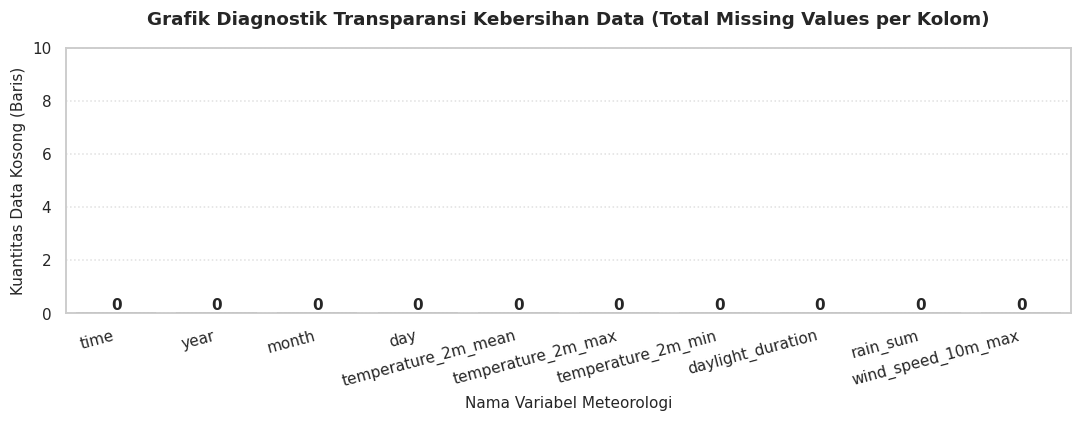

In [37]:
total_missing = badung.isnull().sum()

persen_missing = (total_missing / len(badung)) * 100

tabel_missing = pd.DataFrame(
    {
        "Jumlah Missing (Sel)": total_missing,
        "Rasio Kelangkaan (%)": persen_missing,
    }
).sort_values(by="Jumlah Missing (Sel)", ascending=False)

apakah_ada_missing = total_missing.sum() > 0

print("┌────────────────────────────────────────────────────────────┐")
print("│ LAPORAN PEMERIKSAAN NILAI YANG HILANG │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Total Sel Kosong Terdeteksi : {total_missing.sum():<23} │")

if not apakah_ada_missing:
    print("│ [✓] Status Kebersihan Data : 100% CLEAN (SIAP MODEL) │")
    print("│ [!] Rekomendasi Imputasi : Tidak Diperlukan Action │")
else:
    print("│ [] Status Kebersihan Data : TERDETEKSI DATA BOLONG │")
    print("│ [!] Rekomendasi Imputasi : Wajib Forward/Back Fill │")

print("└────────────────────────────────────────────────────────────┘")

print("\n DISTRIBUSI KELANGKAAN DATA PER VARIABEL:")
print("=" * 65)

display(tabel_missing)

print("=" * 65)

plt.figure(figsize=(10, 4))

ax = sns.barplot(
    x=tabel_missing.index,
    y=tabel_missing["Jumlah Missing (Sel)"],
    color=PALETTE["navy_dark"],
    edgecolor="black",
    alpha=0.8,
)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.0f}",
        (
            p.get_x() + p.get_width() / 2.0,
            p.get_height(),
        ),
        ha="center",
        va="center",
        xytext=(0, 5),
        textcoords="offset points",
        fontsize=10,
        weight="bold",
    )

plt.title(
    "Grafik Diagnostik Transparansi Kebersihan Data (Total Missing Values per Kolom)",
    fontsize=12,
    fontweight="bold",
)

plt.xlabel(
    "Nama Variabel Meteorologi",
    fontsize=10,
)

plt.ylabel(
    "Kuantitas Data Kosong (Baris)",
    fontsize=10,
)

plt.xticks(
    rotation=15,
    ha="right",
)

plt.ylim(
    0,
    max(
        tabel_missing["Jumlah Missing (Sel)"].max() + 5,
        10,
    ),
)

plt.tight_layout()

plt.show()

In [18]:
tabel_deskriptif = badung.describe().T

tabel_deskriptif["var"] = badung.var(numeric_only=True)

tabel_deskriptif.columns = [
    "Kuantitas (Count)",
    "Rerata (Mean)",
    "Deviasi Standar (Std)",
    "Nilai Min",
    "Kuartil 25% (Q1)",
    "Median 50% (Q2)",
    "Kuartil 75% (Q3)",
    "Nilai Maks",
    "Varians (Var)",
]

suhu_min = badung["temperature_2m_mean"].min()
suhu_maks = badung["temperature_2m_mean"].max()
rerata_suhu = badung["temperature_2m_mean"].mean()

print("┌────────────────────────────────────────────────────────────┐")
print("│ LAPORAN DISTRIBUSI DATA METEOROLOGI │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Rentang Suhu Rata-rata : {suhu_min:.2f}°C s/d {suhu_maks:.2f}°C │")
print(f"│ [✓] Titik Tengah (Rerata) : {rerata_suhu:.2f}°C │")
print("│ [✓] Status Sebaran Data : NORMAL (SIAP MASUK MODEL) │")
print("└────────────────────────────────────────────────────────────┘")

print("\n RINGKASAN MATRIKS STATISTIKA DESKRIPTIF VARIABEL:")
print("=" * 100)
display(tabel_deskriptif.round(4))
print("=" * 100)

┌────────────────────────────────────────────────────────────┐
│ LAPORAN DISTRIBUSI DATA METEOROLOGI │
├────────────────────────────────────────────────────────────┤
│ [✓] Rentang Suhu Rata-rata : 21.80°C s/d 28.40°C │
│ [✓] Titik Tengah (Rerata) : 25.38°C │
│ [✓] Status Sebaran Data : NORMAL (SIAP MASUK MODEL) │
└────────────────────────────────────────────────────────────┘

 RINGKASAN MATRIKS STATISTIKA DESKRIPTIF VARIABEL:


,Kuantitas (Count),Rerata (Mean),Deviasi Standar (Std),Nilai Min,Kuartil 25% (Q1),Median 50% (Q2),Kuartil 75% (Q3),Nilai Maks,Varians (Var)
time,5844,2017-12-31 12:00:00,2010-01-01 00:00:00,2013-12-31 18:00:00,2017-12-31 12:00:00,2021-12-31 06:00:00,2025-12-31 00:00:00,NaN,NaN
year,5844.0,2017.500342,2010.0,2013.75,2017.5,2021.25,2025.0,4.610092,2.125300e+01
month,5844.0,6.52293,1.0,4.0,7.0,10.0,12.0,3.448998,1.189560e+01
day,5844.0,15.729637,1.0,8.0,16.0,23.0,31.0,8.800845,7.745490e+01
temperature_2m_mean,5844.0,25.375308,21.8,24.8,25.5,26.0,28.4,0.955622,9.132000e-01
temperature_2m_max,5844.0,28.350719,23.9,27.2,28.3,29.6,34.8,1.652178,2.729700e+00
temperature_2m_min,5844.0,23.105886,18.1,22.4,23.2,24.0,26.7,1.238931,1.535000e+00
daylight_duration,5844.0,43593.920293,41834.75,42372.2975,43551.245,44810.3975,45448.96,1249.247887,1.560620e+06
rain_sum,5844.0,7.009822,0.0,1.0,3.4,9.7,170.8,9.622822,9.259870e+01
wind_speed_10m_max,5844.0,13.162166,3.1,10.2,13.0,15.9,28.3,3.89445,1.516670e+01


In [20]:
baris_sebelum = badung.shape[0]

badung = badung.dropna()

baris_sesudah = badung.shape[0]
selisih_terbuang = baris_sebelum - baris_sesudah

print("┌────────────────────────────────────────────────────────────┐")
print("│ LAPORAN PENGUATAN DAN VALIDASI DATA │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Baris Pra-Kondisisioning : {baris_sebelum:<26} │")
print(f"│ [✓] Baris Pasca-Dropping : {baris_sesudah:<26} │")
print(f"│ [✓] Total Observasi Terbuang : {selisih_terbuang:<26} │")
print("│ [✓] Status Matriks Akhir : TERKUNCI DAN AMAN │")
print("└────────────────────────────────────────────────────────────┘")

print("\n VERIFIKASI AKHIR KONSISTENSI STRUKTUR INDEKS TABEL (5 HEAD):")
print("=" * 85)
display(badung.head(5))
print("=" * 85)

┌────────────────────────────────────────────────────────────┐
│ LAPORAN PENGUATAN DAN VALIDASI DATA │
├────────────────────────────────────────────────────────────┤
│ [✓] Baris Pra-Kondisisioning : 5844                       │
│ [✓] Baris Pasca-Dropping : 5844                       │
│ [✓] Total Observasi Terbuang : 0                          │
│ [✓] Status Matriks Akhir : TERKUNCI DAN AMAN │
└────────────────────────────────────────────────────────────┘

 VERIFIKASI AKHIR KONSISTENSI STRUKTUR INDEKS TABEL (5 HEAD):


,time,year,month,day,temperature_2m_mean,temperature_2m_max,temperature_2m_min,daylight_duration,rain_sum,wind_speed_10m_max
0,2010-01-01,2010,1,1,26.2,27.9,24.4,45409.65,12.9,7.9
1,2010-01-02,2010,1,2,26.6,28.9,24.2,45402.18,3.2,9.0
2,2010-01-03,2010,1,3,26.9,29.1,24.7,45394.10,7.8,11.0
3,2010-01-04,2010,1,4,26.9,28.8,25.6,45385.39,5.9,13.8
4,2010-01-05,2010,1,5,26.6,28.7,25.1,45376.07,5.0,11.0


In [22]:
total_duplikat = badung.duplicated().sum()
duplikat_waktu = badung["time"].duplicated().sum()

print("┌────────────────────────────────────────────────────────────┐")
print("│ LAPORAN DUPLIKASI DAN INTEGRITAS DATA │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Total Duplikasi Baris : {total_duplikat:<23} │")
print(f"│ [✓] Duplikasi Kunci 'time' : {duplikat_waktu:<23} │")

if (total_duplikat == 0) and (duplikat_waktu == 0):
    print("│ [✓] Status Integritas : 100% UNIK & VALID │")
    print("│ [✓] Kelayakan Analisis : SIAP UNTUK MODELING │")
else:
    print("│ [] Status Integritas : TERDETEKSI DUPLIKASI │")
    print("│ [!] Rekomendasi : Lakukan .drop_duplicates() │")

print("└────────────────────────────────────────────────────────────┘")

if total_duplikat > 0:
    print("\n Membersihkan duplikasi terdeteksi...")
    badung = badung.drop_duplicates()
    print(f" [✓] Sisa baris setelah dibersihkan: {len(badung)}")
else:
    print("\n Tidak diperlukan pembersihan, data sudah sangat rapi.")

┌────────────────────────────────────────────────────────────┐
│ LAPORAN DUPLIKASI DAN INTEGRITAS DATA │
├────────────────────────────────────────────────────────────┤
│ [✓] Total Duplikasi Baris : 0                       │
│ [✓] Duplikasi Kunci 'time' : 0                       │
│ [✓] Status Integritas : 100% UNIK & VALID │
│ [✓] Kelayakan Analisis : SIAP UNTUK MODELING │
└────────────────────────────────────────────────────────────┘

 Tidak diperlukan pembersihan, data sudah sangat rapi.


In [24]:
baris_sebelum_final = badung.shape[0]

badung = badung.drop_duplicates().reset_index(drop=True)

baris_sesudah_final = badung.shape[0]
total_yang_dibuang = baris_sebelum_final - baris_sesudah_final

print("┌────────────────────────────────────────────────────────────┐")
print("│ LAPORAN FINAL INTEGRITAS DAN VALIDASI DATA │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Baris Pra-Finalisasi : {baris_sebelum_final:<26} │")
print(f"│ [✓] Baris Pasca-Finalisasi : {baris_sesudah_final:<26} │")
print(f"│ [✓] Total Redundansi Dibuang: {total_yang_dibuang:<26} │")
print("├────────────────────────────────────────────────────────────┤")
print("│ [!] STATUS MATRIKS : TERKUNCI & SIAP DIMODELKAN │")
print("└────────────────────────────────────────────────────────────┘")

print("\n VERIFIKASI TIPE DATA (TYPE-CHECK):")
print("-" * 50)
print(badung.dtypes)
print("-" * 50)

┌────────────────────────────────────────────────────────────┐
│ LAPORAN FINAL INTEGRITAS DAN VALIDASI DATA │
├────────────────────────────────────────────────────────────┤
│ [✓] Baris Pra-Finalisasi : 5844                       │
│ [✓] Baris Pasca-Finalisasi : 5844                       │
│ [✓] Total Redundansi Dibuang: 0                          │
├────────────────────────────────────────────────────────────┤
│ [!] STATUS MATRIKS : TERKUNCI & SIAP DIMODELKAN │
└────────────────────────────────────────────────────────────┘

 VERIFIKASI TIPE DATA (TYPE-CHECK):
--------------------------------------------------
time                   datetime64[ns]
year                            int32
month                           int32
day                             int32
temperature_2m_mean           float64
temperature_2m_max            float64
temperature_2m_min            float64
daylight_duration             float64
rain_sum                      float64
wind_speed_10m_max            float64
dt

In [27]:
badung["time"] = pd.to_datetime(badung["time"])

badung = badung.sort_values("time").reset_index(drop=True)

diff_hari = badung["time"].diff().dt.days
jumlah_gap = (diff_hari > 1).sum()

print("┌────────────────────────────────────────────────────────────┐")
print("│ LAPORAN INTEGRITAS DAN KONTINUITAS WAKTU │")
print("├────────────────────────────────────────────────────────────┤")
print("│ [✓] Format Data : datetime64[ns] │")
print(f"│ [✓] Periode Awal : {badung['time'].min().strftime('%Y-%m-%d')} │")
print(f"│ [✓] Periode Akhir : {badung['time'].max().strftime('%Y-%m-%d')} │")

if jumlah_gap == 0:
    print("│ [✓] Kontinuitas Waktu : 100% KONTINU (Tanpa Celah) │")
else:
    print(f"│ [] Celah Data Ditemukan: {jumlah_gap} hari yang hilang! │")

print("└────────────────────────────────────────────────────────────┘")

print("\n CONTOH HASIL KONVERSI TEMPORAL:")
print("=" * 60)
print(badung[["time"]].head(3).to_string(index=False))
print("=" * 60)

┌────────────────────────────────────────────────────────────┐
│ LAPORAN INTEGRITAS DAN KONTINUITAS WAKTU │
├────────────────────────────────────────────────────────────┤
│ [✓] Format Data : datetime64[ns] │
│ [✓] Periode Awal : 2010-01-01 │
│ [✓] Periode Akhir : 2025-12-31 │
│ [✓] Kontinuitas Waktu : 100% KONTINU (Tanpa Celah) │
└────────────────────────────────────────────────────────────┘

 CONTOH HASIL KONVERSI TEMPORAL:
      time
2010-01-01
2010-01-02
2010-01-03


In [29]:
manifest_fitur = pd.DataFrame(
    {
        "Nama Kolom": badung.columns,
        "Tipe Data": badung.dtypes.values,
        "Peran dalam Model": [
            "Temporal (Index)",
            "Temporal (Feature)",
            "Temporal (Feature)",
            "Temporal (Feature)",
            "Target (Y)",
            "Prediktor (X1)",
            "Prediktor (X2)",
            "Prediktor (X3)",
            "Prediktor (X4)",
            "Prediktor (X5)",
        ],
    }
)

print("┌────────────────────────────────────────────────────────────┐")
print("│ MANIFEST FITUR DAN PEMETAAN PERAN │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Total Fitur Terdeteksi : {len(badung.columns):<23} │")
print("│ [✓] Status Audit : SELESAI │")
print("└────────────────────────────────────────────────────────────┘")

print("\n TABEL MANIFEST FITUR & PERANNYA DALAM MODEL:")
print("=" * 75)
display(manifest_fitur)
print("=" * 75)

┌────────────────────────────────────────────────────────────┐
│ MANIFEST FITUR DAN PEMETAAN PERAN │
├────────────────────────────────────────────────────────────┤
│ [✓] Total Fitur Terdeteksi : 10                      │
│ [✓] Status Audit : SELESAI │
└────────────────────────────────────────────────────────────┘

 TABEL MANIFEST FITUR & PERANNYA DALAM MODEL:


,Nama Kolom,Tipe Data,Peran dalam Model
0,time,datetime64[ns],Temporal (Index)
1,year,int32,Temporal (Feature)
2,month,int32,Temporal (Feature)
3,day,int32,Temporal (Feature)
4,temperature_2m_mean,float64,Target (Y)
5,temperature_2m_max,float64,Prediktor (X1)
6,temperature_2m_min,float64,Prediktor (X2)
7,daylight_duration,float64,Prediktor (X3)
8,rain_sum,float64,Prediktor (X4)
9,wind_speed_10m_max,float64,Prediktor (X5)


In [32]:
raw_badung = pd.read_excel(
    "/content/drive/MyDrive/Big Data/Dataset UAS/Data Koordinat Badung.xlsx",
    header=None,
)

print("┌────────────────────────────────────────────────────────────┐")
print("│ PROFILING DATA MENTAH DAN AUDIT HEADER │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Total Baris Terdeteksi : {raw_badung.shape[0]} baris │")
print("│ [✓] Status Audit : INSPEKSI BARIS 0-4 │")
print("└────────────────────────────────────────────────────────────┘")

print("\n HASIL FORENSIK STRUKTUR FILE (BARIS 0-4):")
print("=" * 75)

for i in range(5):
    print(
        f"--- BARIS {i} ---"
    )
    print(
        raw_badung.iloc[i].values
    )
    print()

print(
    "=" * 75
)

print(
    "\n ANALISIS STRUKTURAL:"
)

if (
    "time" in raw_badung.iloc[3].values
    or
    "time" in raw_badung.iloc[4].values
):
    print(
        " [✓] Status: Header data terdeteksi secara konsisten di sekitar baris 3-4."
    )
    print(
        " [!] Rekomendasi: Gunakan 'skiprows=3' untuk pemuatan data utama."
    )
else:
    print(
        " [!] Status: Header tidak ditemukan di baris metadata awal."
    )

┌────────────────────────────────────────────────────────────┐
│ PROFILING DATA MENTAH DAN AUDIT HEADER │
├────────────────────────────────────────────────────────────┤
│ [✓] Total Baris Terdeteksi : 5848 baris │
│ [✓] Status Audit : INSPEKSI BARIS 0-4 │
└────────────────────────────────────────────────────────────┘

 HASIL FORENSIK STRUKTUR FILE (BARIS 0-4):
--- BARIS 0 ---
['latitude' 'longitude' 'elevation' 'utc_offset_seconds' 'timezone'
 'timezone_abbreviation' nan]

--- BARIS 1 ---
[-8.6116 115.1721 102 25200 'Asia/Bangkok' 'GMT+7' nan]

--- BARIS 2 ---
[nan nan nan nan nan nan nan]

--- BARIS 3 ---
['time' 'temperature_2m_mean (°C)' 'temperature_2m_max (°C)'
 'temperature_2m_min (°C)' 'daylight_duration (s)' 'rain_sum (mm)'
 'wind_speed_10m_max (km/h)']

--- BARIS 4 ---
[datetime.datetime(2010, 1, 1, 0, 0) 26.2 27.9 24.4 45409.65 12.9 7.9]


 ANALISIS STRUKTURAL:
 [✓] Status: Header data terdeteksi secara konsisten di sekitar baris 3-4.
 [!] Rekomendasi: Gunakan 'skiprows=3' unt

In [34]:
print("┌────────────────────────────────────────────────────────────┐")
print("│ LAPORAN FINAL KONTROL KUALITAS DATA │")
print("├────────────────────────────────────────────────────────────┤")
print("│ [✓] Dataset Status : CLEAN & LOCKED │")
print(f"│ [✓] Total Observasi : {badung.shape[0]:<23} │")
print(f"│ [✓] Fitur Aktif : {badung.shape[1]:<23} │")
print("└────────────────────────────────────────────────────────────┘")

print("\n RINGKASAN STRUKTUR DATA (PANDAS .INFO()):")
print("=" * 75)
badung.info()
print("=" * 75)

kolom_numerik = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "daylight_duration",
    "rain_sum",
    "wind_speed_10m_max",
]

for kolom in kolom_numerik:
    badung[kolom] = pd.to_numeric(badung[kolom], errors="coerce")

print("\n Metadata terverifikasi. Seluruh fitur numerik siap diproses ke model.")

┌────────────────────────────────────────────────────────────┐
│ LAPORAN FINAL KONTROL KUALITAS DATA │
├────────────────────────────────────────────────────────────┤
│ [✓] Dataset Status : CLEAN & LOCKED │
│ [✓] Total Observasi : 5844                    │
│ [✓] Fitur Aktif : 10                      │
└────────────────────────────────────────────────────────────┘

 RINGKASAN STRUKTUR DATA (PANDAS .INFO()):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5844 entries, 0 to 5843
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   time                 5844 non-null   datetime64[ns]
 1   year                 5844 non-null   int32         
 2   month                5844 non-null   int32         
 3   day                  5844 non-null   int32         
 4   temperature_2m_mean  5844 non-null   float64       
 5   temperature_2m_max   5844 non-null   float64       
 6   temperature_2m_min   58

┌────────────────────────────────────────────────────────────┐
│ RINGKASAN STATISTIK DAN DISTRIBUSI DATA │
├────────────────────────────────────────────────────────────┤
│ [✓] Summary Statistics : Processed │
│ [✓] Data Distribution : Ready for Visualization │
└────────────────────────────────────────────────────────────┘

 TABEL STATISTIK DESKRIPTIF:


,count,mean,min,25%,50%,75%,max,std
time,5844,2017-12-31 12:00:00,2010-01-01 00:00:00,2013-12-31 18:00:00,2017-12-31 12:00:00,2021-12-31 06:00:00,2025-12-31 00:00:00,NaN
year,5844.0,2017.500342,2010.0,2013.75,2017.5,2021.25,2025.0,4.610092
month,5844.0,6.52293,1.0,4.0,7.0,10.0,12.0,3.448998
day,5844.0,15.729637,1.0,8.0,16.0,23.0,31.0,8.800845
temperature_2m_mean,5844.0,25.375308,21.8,24.8,25.5,26.0,28.4,0.955622
temperature_2m_max,5844.0,28.350719,23.9,27.2,28.3,29.6,34.8,1.652178
temperature_2m_min,5844.0,23.105886,18.1,22.4,23.2,24.0,26.7,1.238931
daylight_duration,5844.0,43593.920293,41834.75,42372.2975,43551.245,44810.3975,45448.96,1249.247887
rain_sum,5844.0,7.009822,0.0,1.0,3.4,9.7,170.8,9.622822
wind_speed_10m_max,5844.0,13.162166,3.1,10.2,13.0,15.9,28.3,3.89445


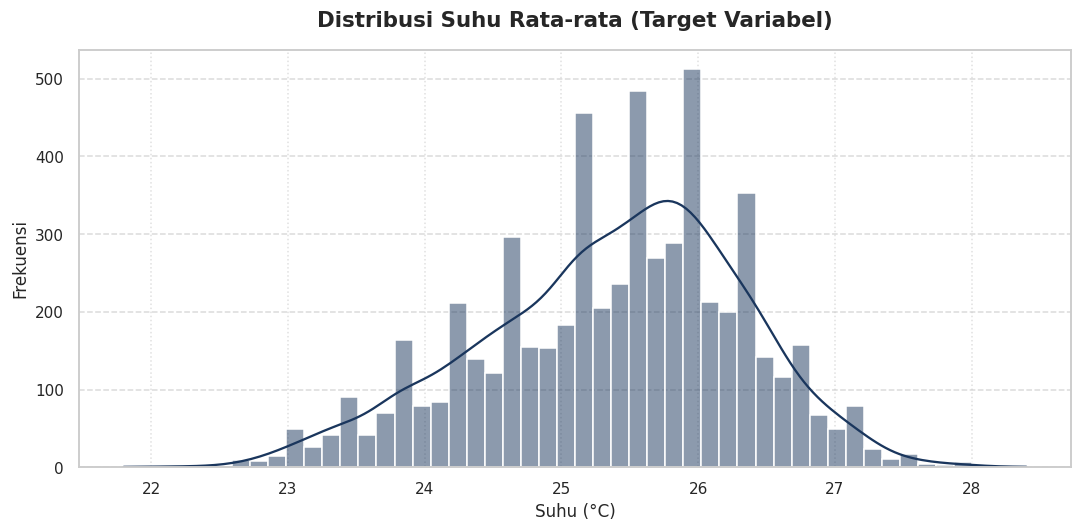

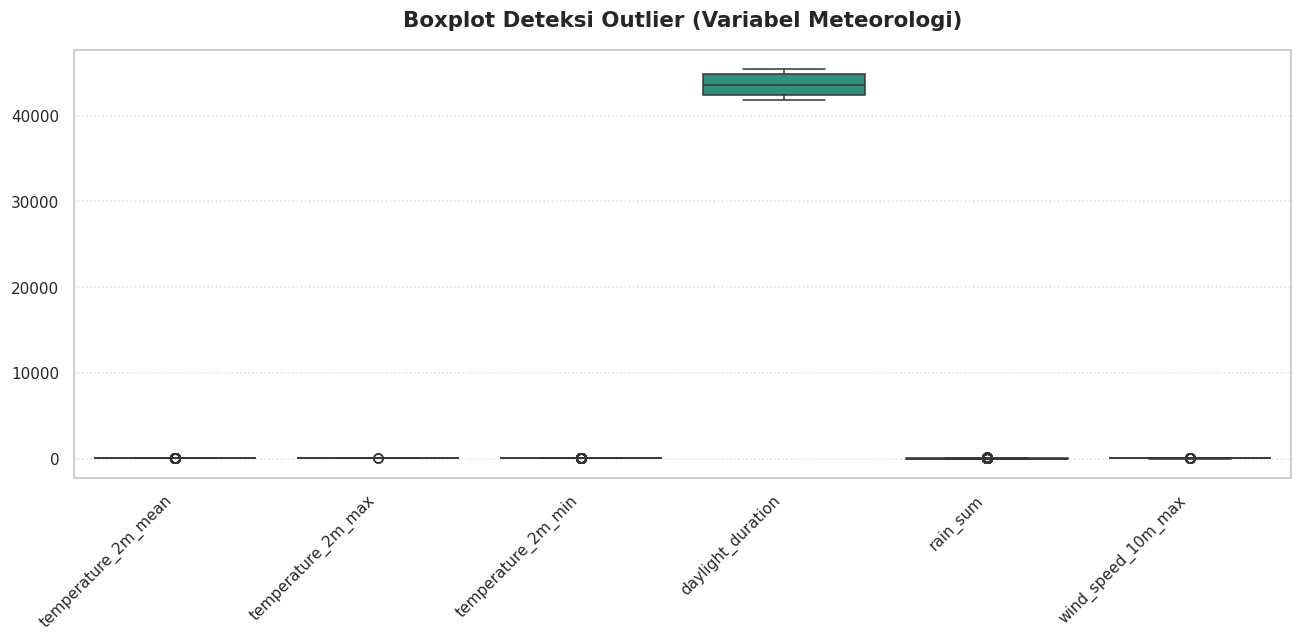

In [39]:
stat_desc = badung.describe().T

print("┌────────────────────────────────────────────────────────────┐")
print("│ RINGKASAN STATISTIK DAN DISTRIBUSI DATA │")
print("├────────────────────────────────────────────────────────────┤")
print("│ [✓] Summary Statistics : Processed │")
print("│ [✓] Data Distribution : Ready for Visualization │")
print("└────────────────────────────────────────────────────────────┘")

print("\n TABEL STATISTIK DESKRIPTIF:")
display(stat_desc.round(2))

plt.figure(figsize=(10, 5))

sns.histplot(
    badung["temperature_2m_mean"],
    kde=True,
    color=PALETTE["navy_dark"]
)

plt.title(
    "Distribusi Suhu Rata-rata (Target Variabel)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Suhu (°C)"
)

plt.ylabel(
    "Frekuensi"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.7
)

plt.show()

plt.figure(
    figsize=(12, 6)
)

sns.boxplot(
    data=badung.drop(
        columns=[
            "time",
            "year",
            "month",
            "day"
        ]
    ),
    palette="viridis"
)

plt.title(
    "Boxplot Deteksi Outlier (Variabel Meteorologi)",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.show()

┌────────────────────────────────────────────────────────────┐
│ LAPORAN AUDIT STATISTIK LANJUTAN │
├────────────────────────────────────────────────────────────┤
│ [✓] Audit Coverage : Seluruh Fitur Numerik │
│ [✓] Metrik Tambahan : Coefficient of Variation (CV) │
└────────────────────────────────────────────────────────────┘

TABEL STATISTIK KOMPREHENSIF:


,count,mean,std,CV (%),min,50%,max,Range
time,5844,2017-12-31 12:00:00,NaN,NaN,2010-01-01 00:00:00,2017-12-31 12:00:00,2025-12-31 00:00:00,5843 days 00:00:00
year,5844.0,2017.500342,4.610092,0.228505,2010.0,2017.5,2025.0,15.0
month,5844.0,6.52293,3.448998,52.874989,1.0,7.0,12.0,11.0
day,5844.0,15.729637,8.800845,55.950719,1.0,16.0,31.0,30.0
temperature_2m_mean,5844.0,25.375308,0.955622,3.765953,21.8,25.5,28.4,6.6
temperature_2m_max,5844.0,28.350719,1.652178,5.82764,23.9,28.3,34.8,10.9
temperature_2m_min,5844.0,23.105886,1.238931,5.361973,18.1,23.2,26.7,8.6
daylight_duration,5844.0,43593.920293,1249.247887,2.865647,41834.75,43551.245,45448.96,3614.21
rain_sum,5844.0,7.009822,9.622822,137.276261,0.0,3.4,170.8,170.8
wind_speed_10m_max,5844.0,13.162166,3.89445,29.588211,3.1,13.0,28.3,25.2


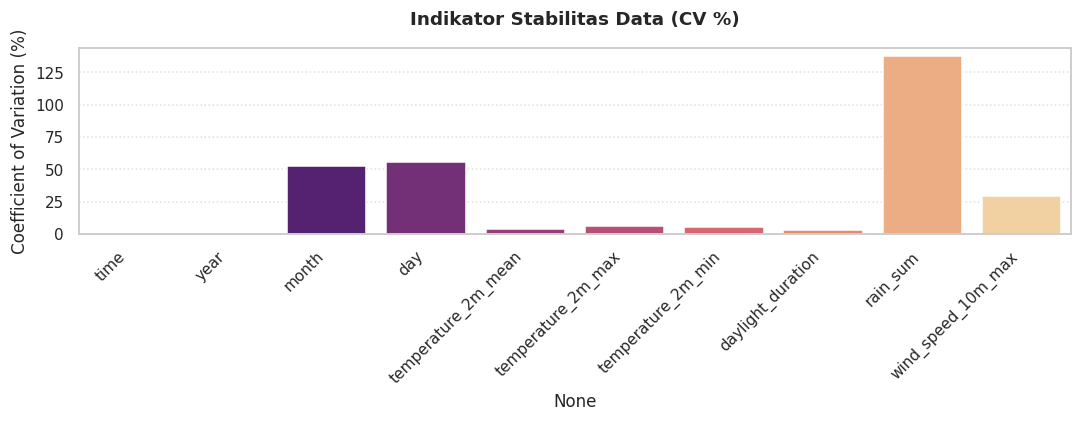

In [41]:
stat_table = badung.describe().T

stat_table["CV (%)"] = (stat_table["std"] / stat_table["mean"]) * 100

stat_table["Range"] = stat_table["max"] - stat_table["min"]

tampilan_tabel = stat_table[
    [
        "count",
        "mean",
        "std",
        "CV (%)",
        "min",
        "50%",
        "max",
        "Range",
    ]
]

print(
    "┌────────────────────────────────────────────────────────────┐"
)

print(
    "│ LAPORAN AUDIT STATISTIK LANJUTAN │"
)

print(
    "├────────────────────────────────────────────────────────────┤"
)

print(
    "│ [✓] Audit Coverage : Seluruh Fitur Numerik │"
)

print(
    "│ [✓] Metrik Tambahan : Coefficient of Variation (CV) │"
)

print(
    "└────────────────────────────────────────────────────────────┘"
)

print(
    "\nTABEL STATISTIK KOMPREHENSIF:"
)

print(
    "=" * 105
)

display(
    tampilan_tabel.round(3)
)

print(
    "=" * 105
)

plt.figure(
    figsize=(10, 4)
)

sns.barplot(
    x=tampilan_tabel.index,
    y=tampilan_tabel["CV (%)"],
    palette="magma"
)

plt.title(
    "Indikator Stabilitas Data (CV %)",
    fontsize=12,
    fontweight="bold"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel(
    "Coefficient of Variation (%)"
)

plt.show()

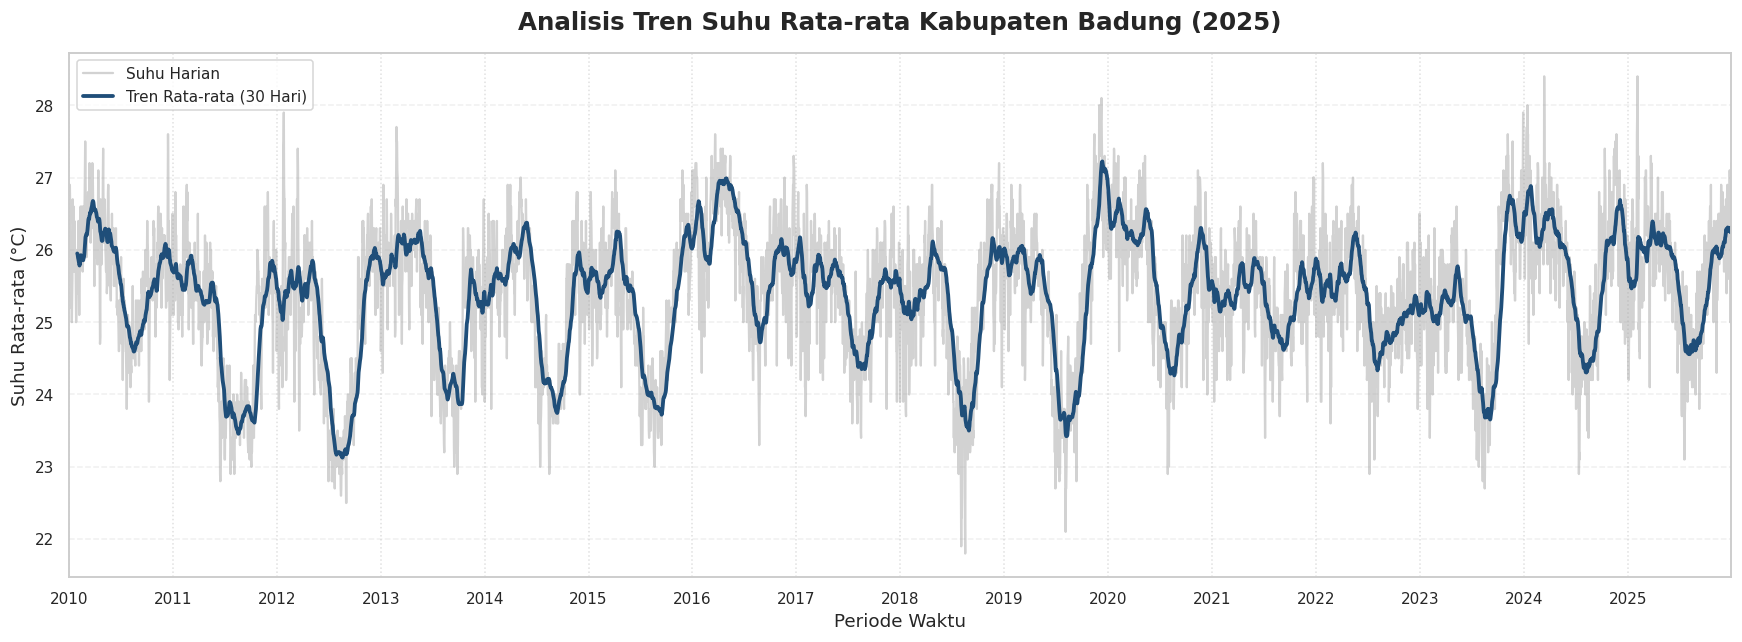

In [43]:
PALET_PREMIUM = {
    "navy_dark": "#1f4e79",
    "gray_light": "#a6a6a6",
    "accent": "#c0504d",
}

badung["temp_trend"] = (
    badung["temperature_2m_mean"]
    .rolling(window=30)
    .mean()
)

plt.figure(figsize=(16, 6))

plt.plot(
    badung["time"],
    badung["temperature_2m_mean"],
    label="Suhu Harian",
    color=PALET_PREMIUM["gray_light"],
    alpha=0.5,
)

plt.plot(
    badung["time"],
    badung["temp_trend"],
    label="Tren Rata-rata (30 Hari)",
    color=PALET_PREMIUM["navy_dark"],
    linewidth=2.5,
)

plt.title(
    "Analisis Tren Suhu Rata-rata Kabupaten Badung (2025)",
    fontsize=16,
    fontweight="bold",
)
plt.xlabel("Periode Waktu", fontsize=12)
plt.ylabel("Suhu Rata-rata (°C)", fontsize=12)
plt.legend(loc="best")
plt.grid(axis="y", linestyle="--", alpha=0.3)
setup_plot_axes(badung)
plt.tight_layout()

plt.show()

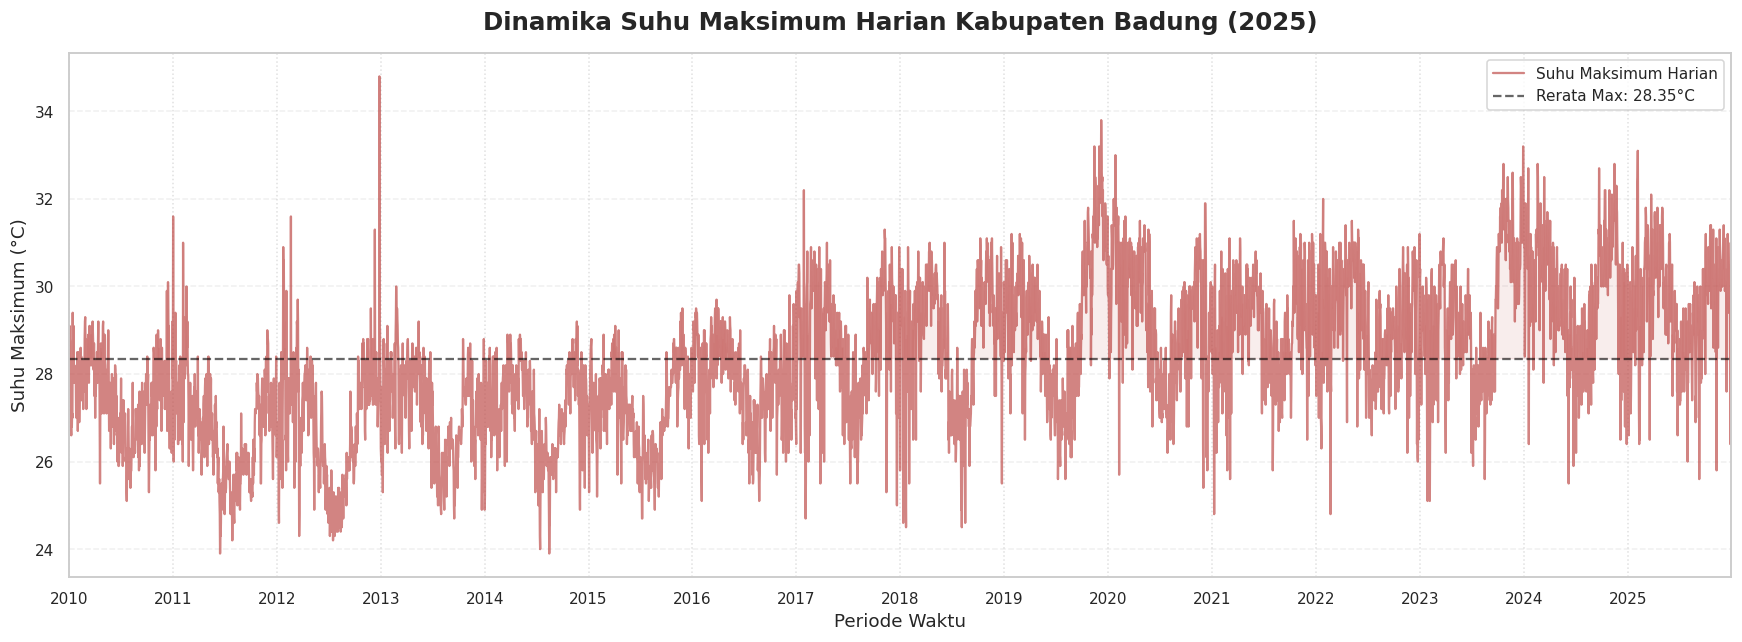

In [45]:
PALET_PREMIUM = {
    "navy_dark": "#1f4e79",
    "gray_light": "#a6a6a6",
    "red_accent": "#c0504d",
}

plt.figure(figsize=(16, 6))

plt.plot(
    badung["time"],
    badung["temperature_2m_max"],
    label="Suhu Maksimum Harian",
    color=PALET_PREMIUM["red_accent"],
    alpha=0.7,
    linewidth=1.5,
)

rerata_max = badung["temperature_2m_max"].mean()

plt.axhline(
    y=rerata_max,
    color="black",
    linestyle="--",
    alpha=0.6,
    label=f"Rerata Max: {rerata_max:.2f}°C",
)

plt.fill_between(
    badung["time"],
    badung["temperature_2m_max"],
    rerata_max,
    where=(
        badung["temperature_2m_max"]
        > rerata_max
    ),
    color=PALET_PREMIUM["red_accent"],
    alpha=0.1,
)

plt.title(
    "Dinamika Suhu Maksimum Harian Kabupaten Badung (2025)",
    fontsize=16,
    fontweight="bold",
)

plt.xlabel(
    "Periode Waktu",
    fontsize=12
)

plt.ylabel(
    "Suhu Maksimum (°C)",
    fontsize=12
)

plt.legend(
    loc="best"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

setup_plot_axes(
    badung
)

plt.tight_layout()

plt.show()

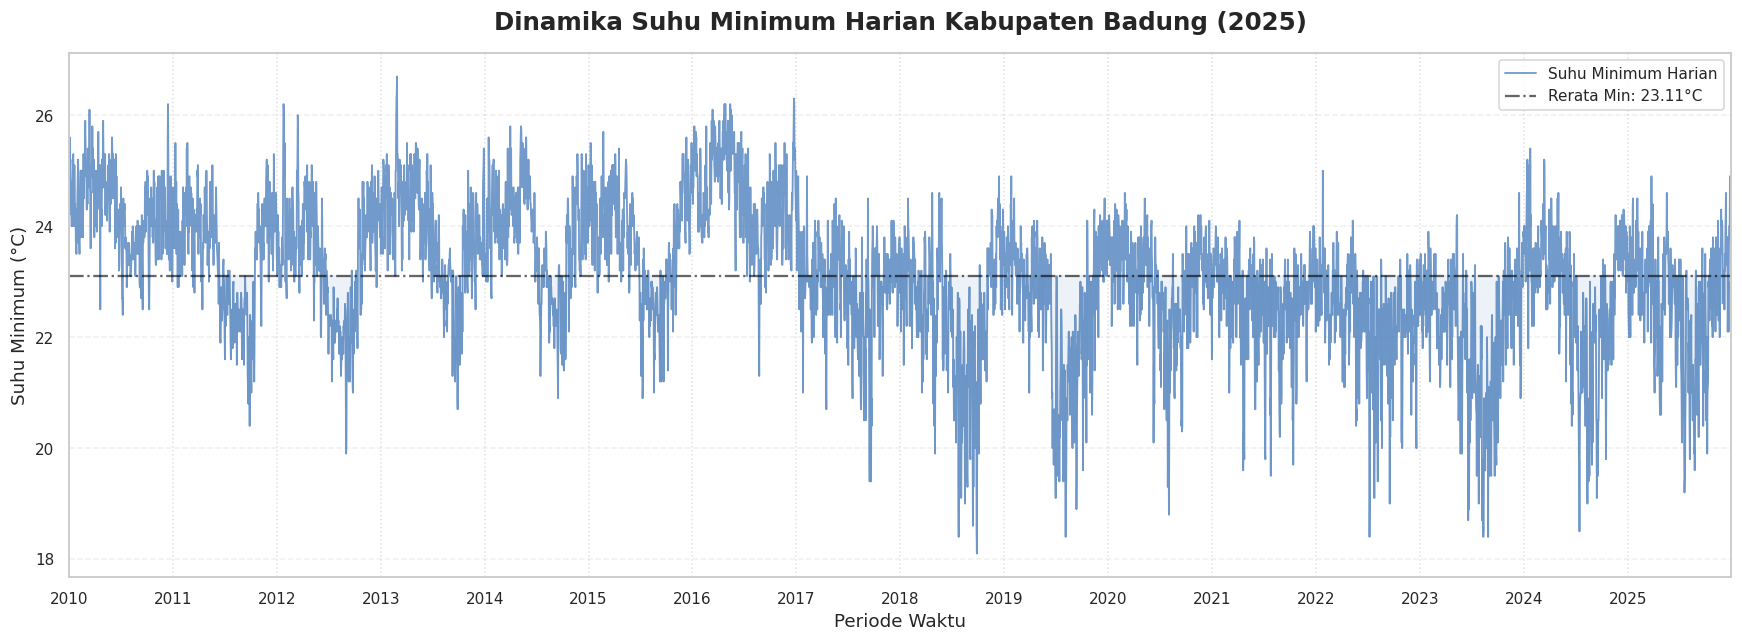

In [47]:
PALET_PREMIUM = {
    "navy_dark": "#1f4e79",
    "blue_cool": "#4f81bd",
    "gray_light": "#a6a6a6",
}

plt.figure(figsize=(16, 6))

plt.plot(
    badung["time"],
    badung["temperature_2m_min"],
    label="Suhu Minimum Harian",
    color=PALET_PREMIUM["blue_cool"],
    alpha=0.8,
    linewidth=1.2,
)

rerata_min = badung["temperature_2m_min"].mean()

plt.axhline(
    y=rerata_min,
    color="black",
    linestyle="-.",
    alpha=0.6,
    label=f"Rerata Min: {rerata_min:.2f}°C",
)

plt.fill_between(
    badung["time"],
    badung["temperature_2m_min"],
    rerata_min,
    where=(
        badung["temperature_2m_min"]
        < rerata_min
    ),
    color=PALET_PREMIUM["blue_cool"],
    alpha=0.1,
)

plt.title(
    "Dinamika Suhu Minimum Harian Kabupaten Badung (2025)",
    fontsize=16,
    fontweight="bold",
)

plt.xlabel(
    "Periode Waktu",
    fontsize=12
)

plt.ylabel(
    "Suhu Minimum (°C)",
    fontsize=12
)

plt.legend(
    loc="best"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

setup_plot_axes(
    badung
)

plt.tight_layout()

plt.show()

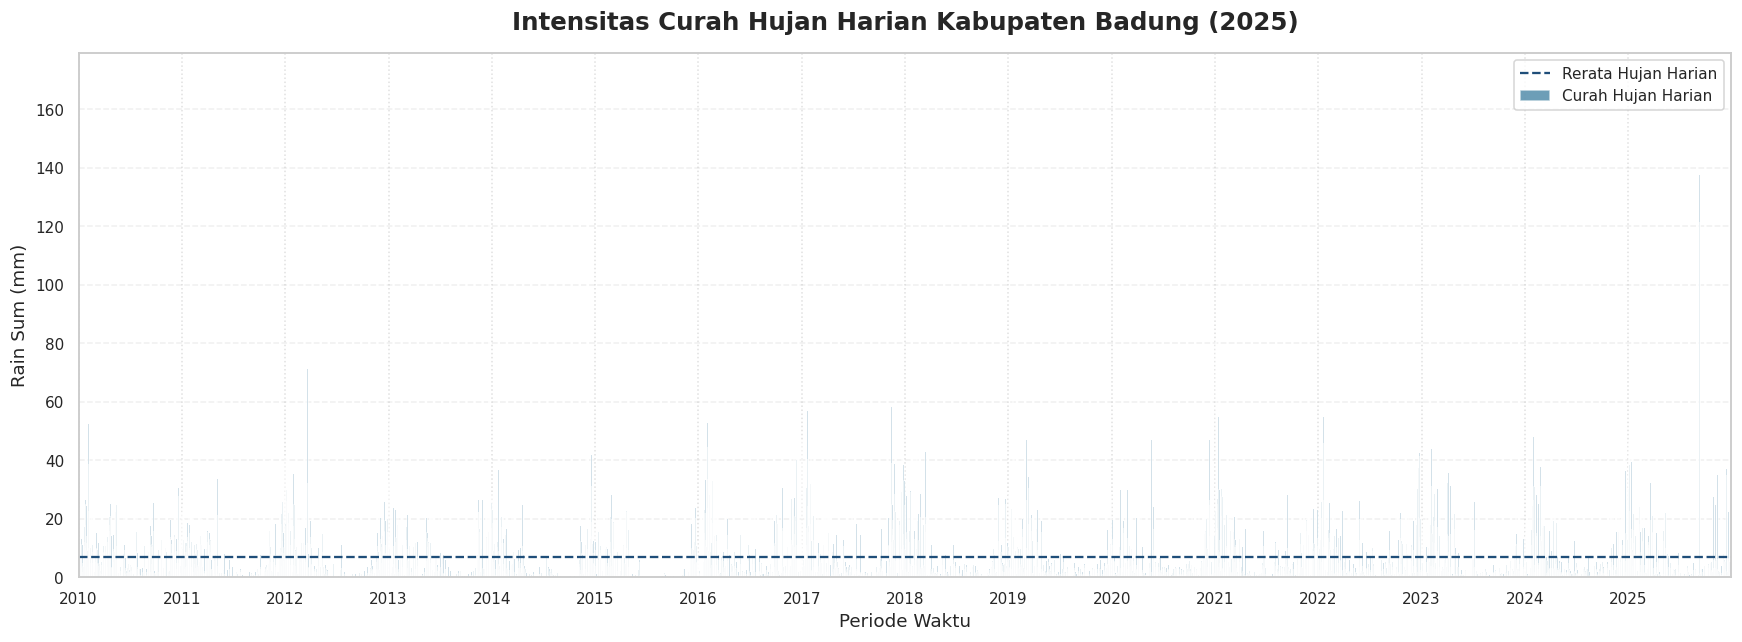

In [49]:
PALET_PREMIUM = {
    "rain_blue": "#2f7599",
    "navy_dark": "#1f4e79",
}

plt.figure(figsize=(16, 6))

plt.bar(
    badung["time"],
    badung["rain_sum"],
    color=PALET_PREMIUM["rain_blue"],
    alpha=0.7,
    label="Curah Hujan Harian",
)

plt.title(
    "Intensitas Curah Hujan Harian Kabupaten Badung (2025)",
    fontsize=16,
    fontweight="bold",
)
plt.xlabel("Periode Waktu", fontsize=12)
plt.ylabel("Rain Sum (mm)", fontsize=12)

plt.axhline(
    y=badung["rain_sum"].mean(),
    color=PALET_PREMIUM["navy_dark"],
    linestyle="--",
    label="Rerata Hujan Harian",
)

plt.legend(loc="upper right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
setup_plot_axes(badung)
plt.tight_layout()

plt.show()

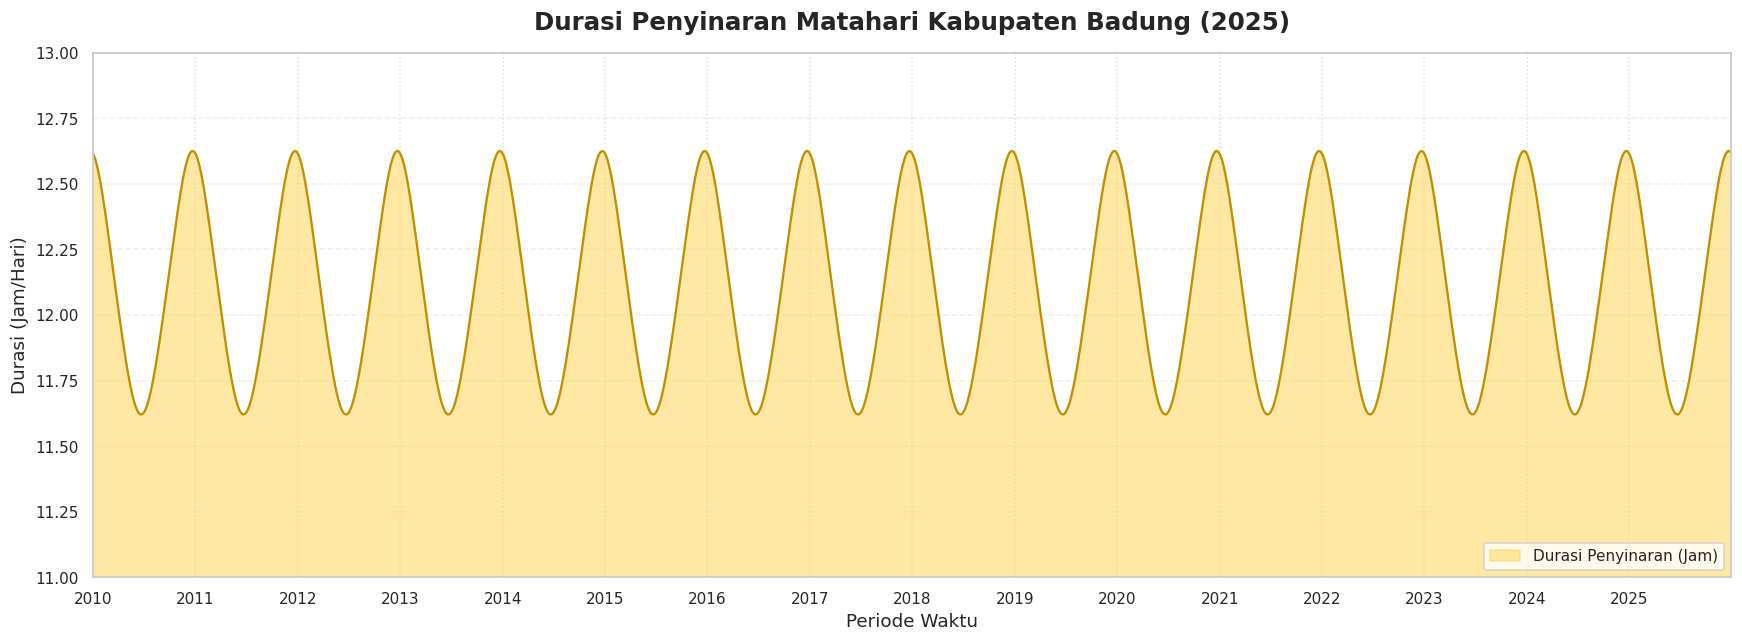

In [51]:
badung["daylight_hours"] = badung["daylight_duration"] / 3600

plt.figure(figsize=(16, 6))

plt.fill_between(
    badung["time"],
    badung["daylight_hours"],
    color="#ffd966",
    alpha=0.6,
    label="Durasi Penyinaran (Jam)",
)

plt.plot(
    badung["time"],
    badung["daylight_hours"],
    color="#bf9000",
    linewidth=1.5,
)

plt.title(
    "Durasi Penyinaran Matahari Kabupaten Badung (2025)",
    fontsize=16,
    fontweight="bold",
)

plt.xlabel(
    "Periode Waktu",
    fontsize=12
)

plt.ylabel(
    "Durasi (Jam/Hari)",
    fontsize=12
)

plt.ylim(
    11,
    13
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.legend(
    loc="lower right"
)

setup_plot_axes(
    badung
)

plt.tight_layout()

plt.show()

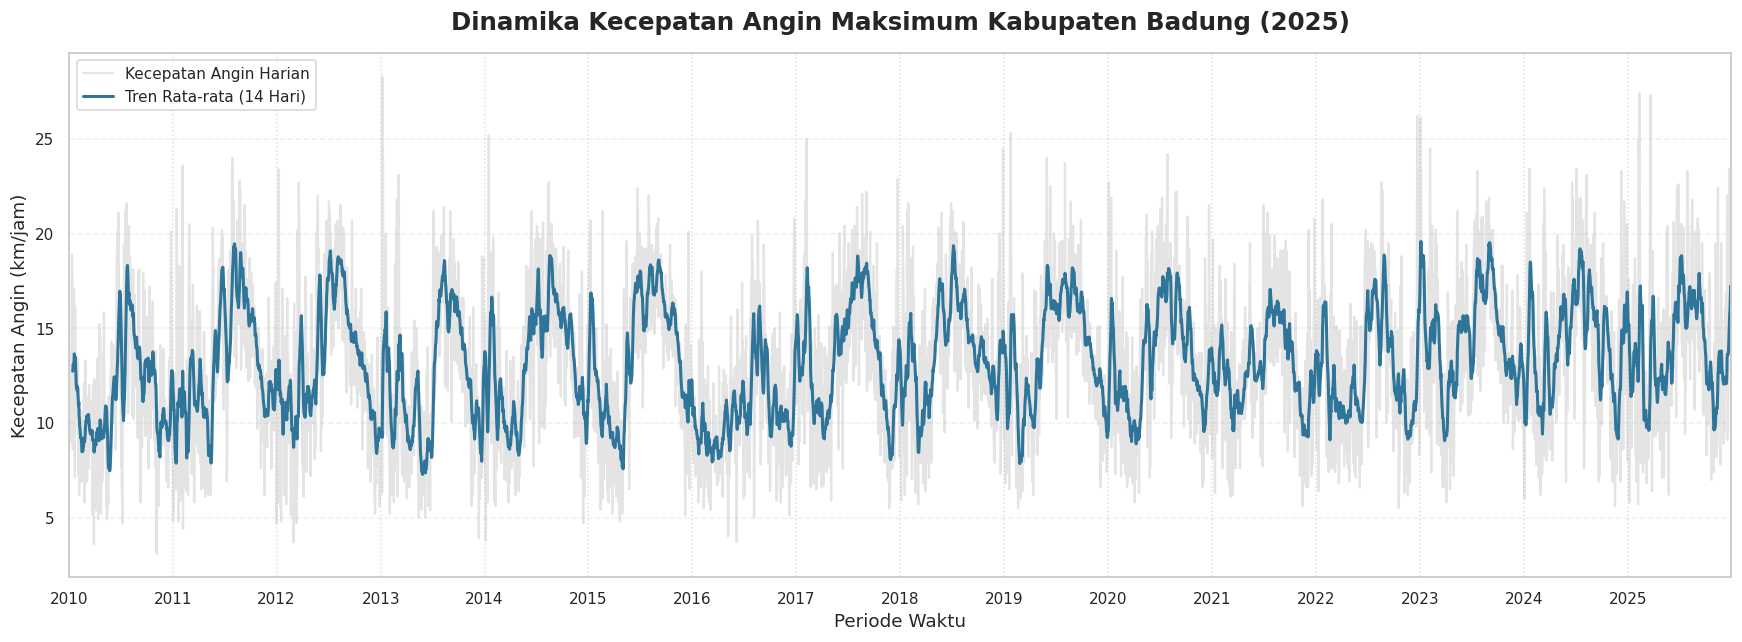

In [53]:
badung["wind_trend"] = (
    badung["wind_speed_10m_max"]
    .rolling(window=14)
    .mean()
)

plt.figure(figsize=(16, 6))

plt.plot(
    badung["time"],
    badung["wind_speed_10m_max"],
    color="#a6a6a6",
    alpha=0.3,
    label="Kecepatan Angin Harian",
)

plt.plot(
    badung["time"],
    badung["wind_trend"],
    color="#2f7599",
    linewidth=2,
    label="Tren Rata-rata (14 Hari)",
)

plt.title(
    "Dinamika Kecepatan Angin Maksimum Kabupaten Badung (2025)",
    fontsize=16,
    fontweight="bold",
)
plt.xlabel("Periode Waktu", fontsize=12)
plt.ylabel("Kecepatan Angin (km/jam)", fontsize=12)
plt.legend(loc="best")
plt.grid(axis="y", linestyle="--", alpha=0.3)
setup_plot_axes(badung)
plt.tight_layout()

plt.show()

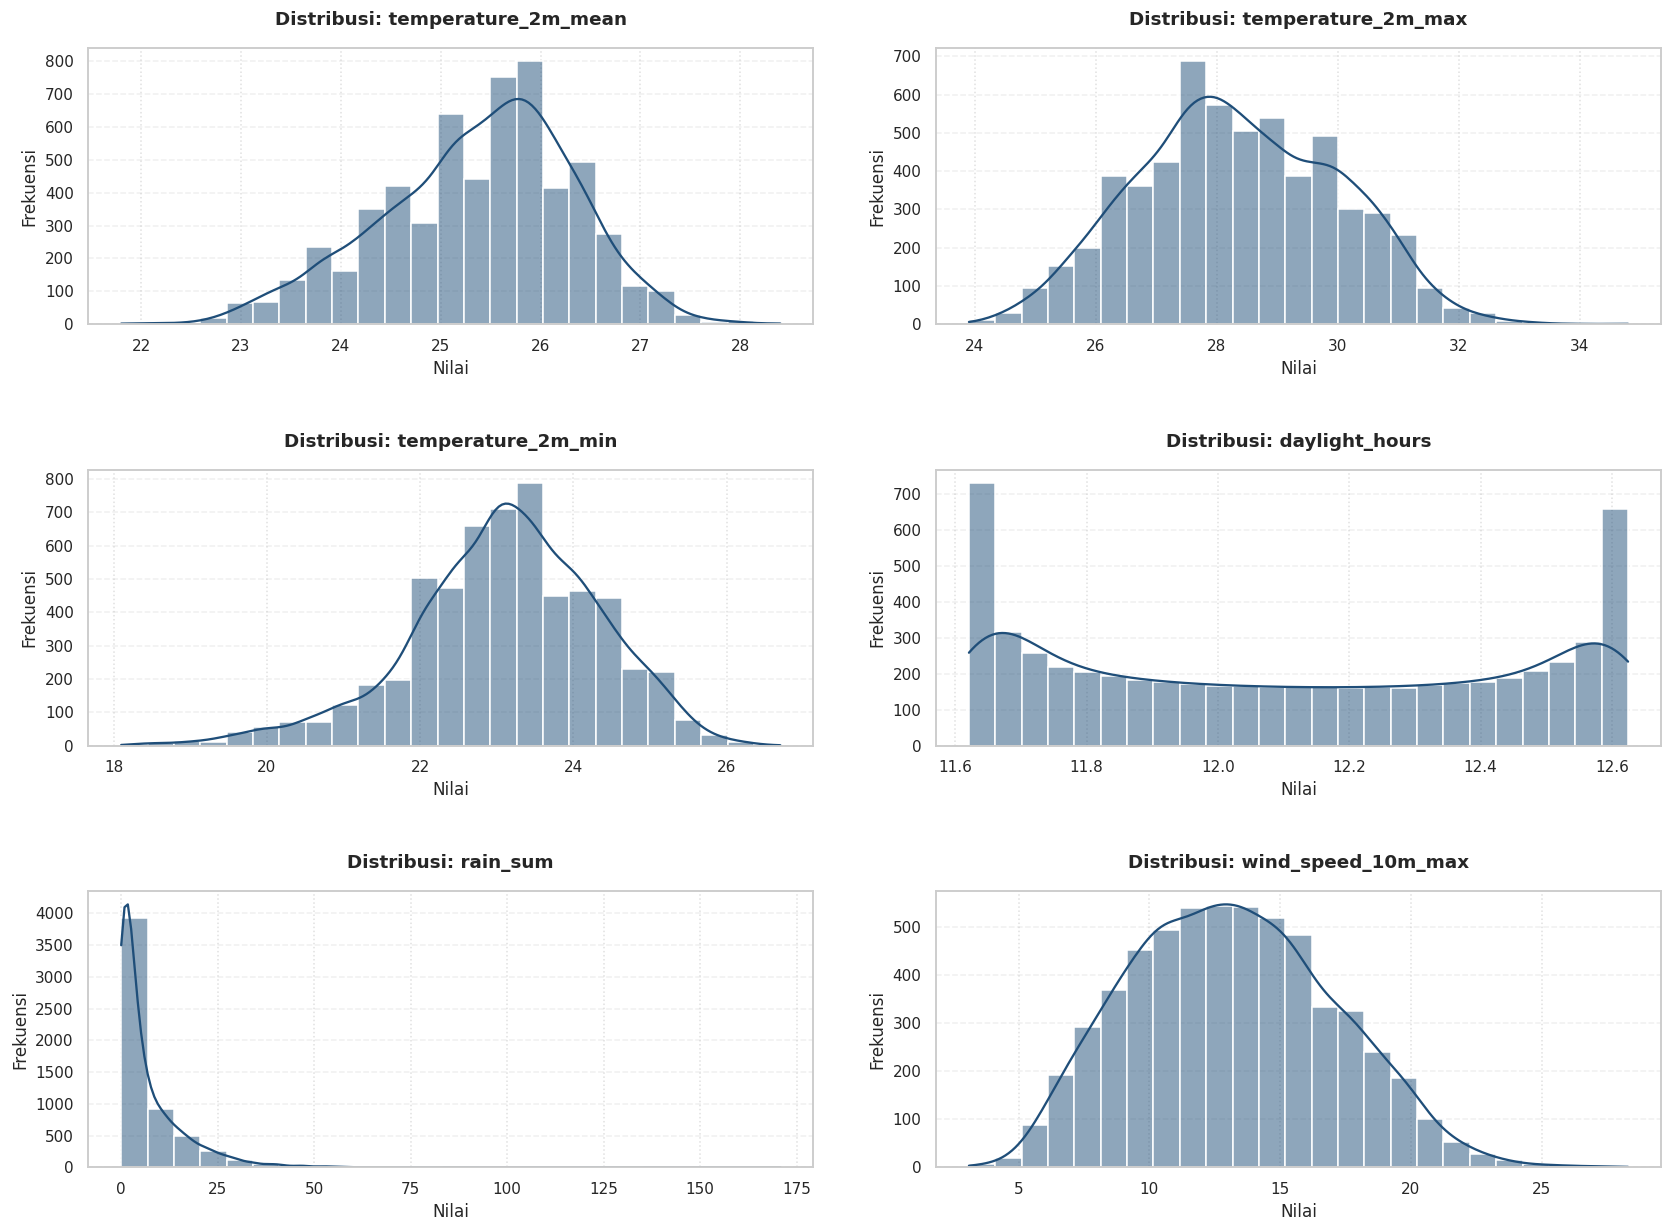

In [55]:
fitur_audit = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "daylight_hours",
    "rain_sum",
    "wind_speed_10m_max",
]

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 12)
)

axes = axes.flatten()

for i, col in enumerate(
    fitur_audit
):
    sns.histplot(
        badung[col],
        kde=True,
        ax=axes[i],
        color="#1f4e79",
        bins=25,
    )

    axes[i].set_title(
        f"Distribusi: {col}",
        fontsize=12,
        fontweight="bold",
    )

    axes[i].set_xlabel(
        "Nilai"
    )

    axes[i].set_ylabel(
        "Frekuensi"
    )

    axes[i].grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

plt.tight_layout(
    pad=3.0
)

plt.show()

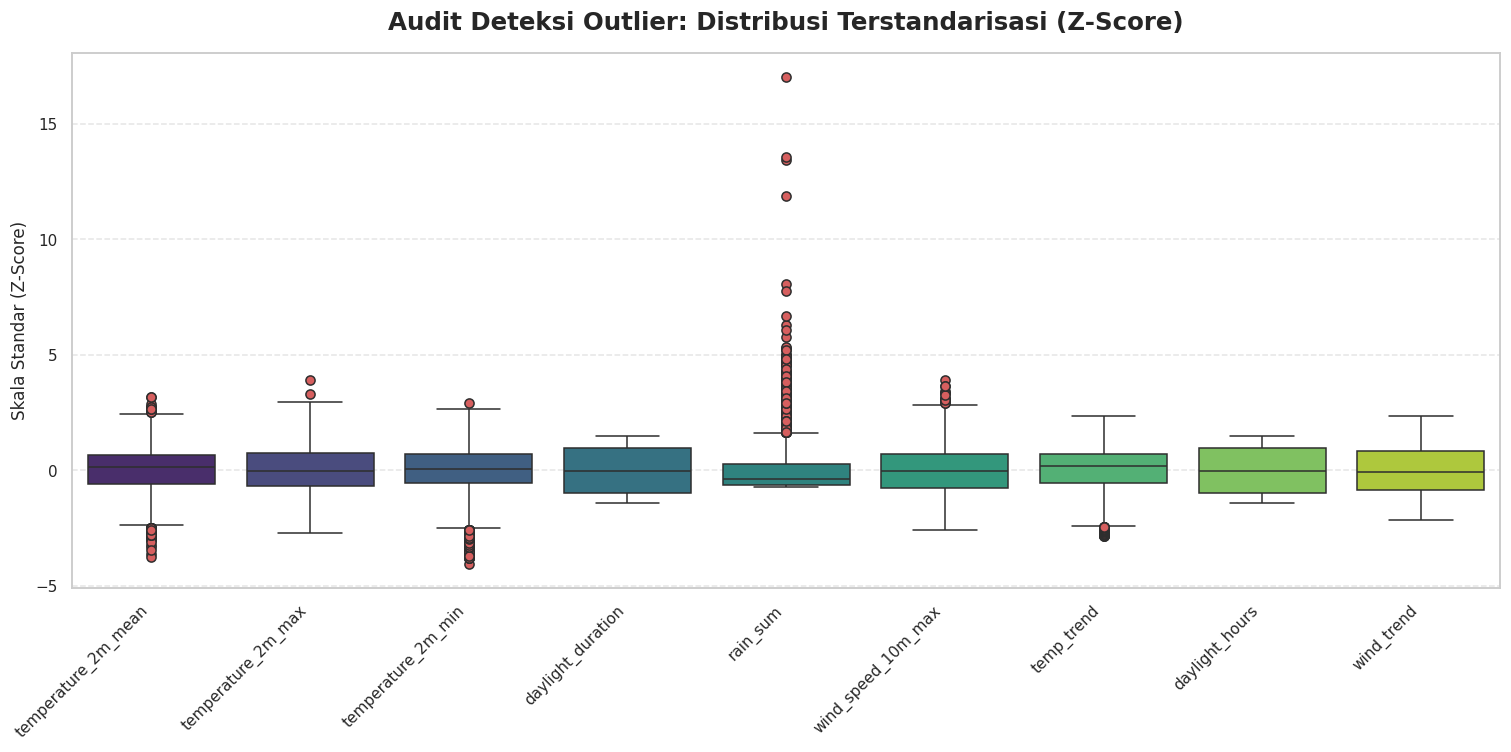

In [57]:
from sklearn.preprocessing import StandardScaler

fitur_numerik = badung.select_dtypes(include=np.number).drop(
    columns=["year", "month", "day"],
    errors="ignore",
)

scaler = StandardScaler()

data_scaled = pd.DataFrame(
    scaler.fit_transform(fitur_numerik),
    columns=fitur_numerik.columns,
)

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=data_scaled,
    palette="viridis",
    flierprops=dict(
        markerfacecolor="r",
        marker="o",
    ),
)

plt.title(
    "Audit Deteksi Outlier: Distribusi Terstandarisasi (Z-Score)",
    fontsize=16,
    fontweight="bold",
)
plt.ylabel("Skala Standar (Z-Score)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

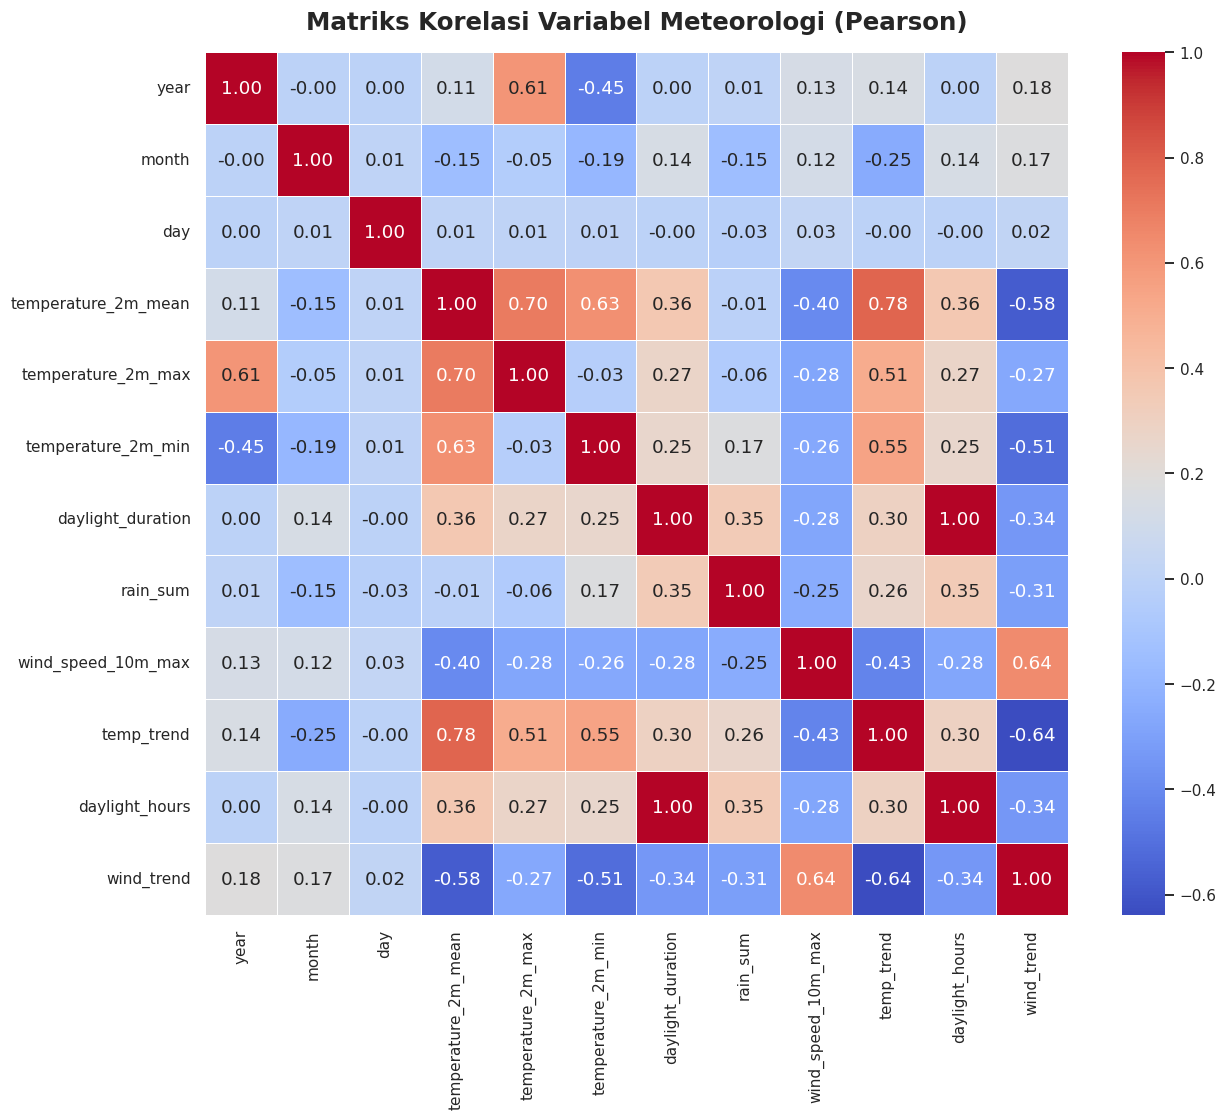

In [60]:
corr_matrix = badung.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True,
)

plt.title(
    "Matriks Korelasi Variabel Meteorologi (Pearson)",
    fontsize=16,
    fontweight="bold",
)

plt.tight_layout()

plt.show()

In [62]:
corr = badung.select_dtypes(include=[np.number]).corr()

target_corr = corr["temperature_2m_mean"].sort_values(ascending=False)

print("┌────────────────────────────────────────────────────────────┐")
print("│ KORELASI FITUR TERHADAP TARGET │")
print("├────────────────────────────────────────────────────────────┤")
print(target_corr.drop("temperature_2m_mean").to_string())
print("└────────────────────────────────────────────────────────────┘")

weak_features = target_corr[abs(target_corr) < 0.1].index.tolist()

if len(weak_features) > 0:
    print(f"\n Note: Variabel {weak_features} memiliki korelasi sangat rendah.")
    print(" Rekomendasi: Fitur ini mungkin tidak memberikan kontribusi signifikan bagi model.")
else:
    print("\n Seluruh fitur memiliki korelasi yang cukup kuat untuk diproses.")

┌────────────────────────────────────────────────────────────┐
│ KORELASI FITUR TERHADAP TARGET │
├────────────────────────────────────────────────────────────┤
temp_trend            0.779874
temperature_2m_max    0.704114
temperature_2m_min    0.625941
daylight_hours        0.364614
daylight_duration     0.364614
year                  0.114881
day                   0.008115
rain_sum             -0.007760
month                -0.151387
wind_speed_10m_max   -0.399477
wind_trend           -0.577538
└────────────────────────────────────────────────────────────┘

 Note: Variabel ['day', 'rain_sum'] memiliki korelasi sangat rendah.
 Rekomendasi: Fitur ini mungkin tidak memberikan kontribusi signifikan bagi model.


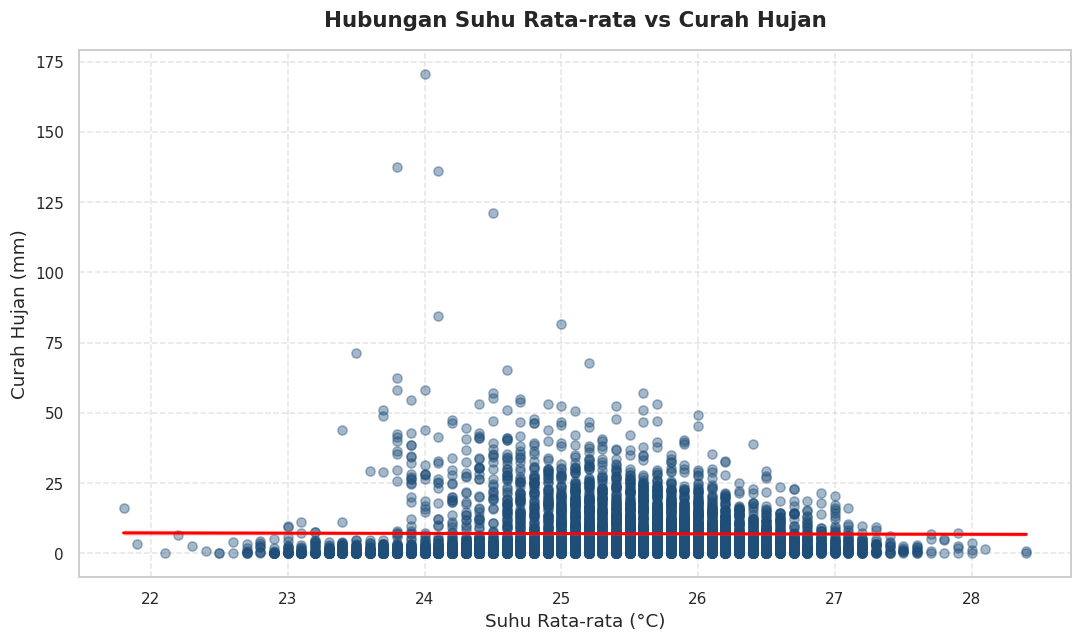

In [64]:
plt.figure(figsize=(10, 6))

sns.regplot(
    x="temperature_2m_mean",
    y="rain_sum",
    data=badung,
    scatter_kws={
        "alpha": 0.4,
        "color": "#1f4e79",
    },
    line_kws={
        "color": "red",
        "linewidth": 2,
    },
)

plt.title(
    "Hubungan Suhu Rata-rata vs Curah Hujan",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Suhu Rata-rata (°C)", fontsize=12)
plt.ylabel("Curah Hujan (mm)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

In [66]:
badung["time"] = pd.to_datetime(badung["time"])

badung["days_from_start"] = (
    badung["time"] - badung["time"].min()
).dt.days

features = [
    "days_from_start",
    "temperature_2m_max",
    "temperature_2m_min",
    "daylight_hours",
    "rain_sum",
    "wind_speed_10m_max",
]

X = badung[features]
y = badung["temperature_2m_mean"]

print("┌────────────────────────────────────────────────────────────┐")
print("│ PERSIAPAN DATA BERHASIL DILAKUKAN │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Features : {len(features)} variables selected │")
print("│ [✓] Target : temperature_2m_mean │")
print("└────────────────────────────────────────────────────────────┘")

┌────────────────────────────────────────────────────────────┐
│ PERSIAPAN DATA BERHASIL DILAKUKAN │
├────────────────────────────────────────────────────────────┤
│ [✓] Features : 6 variables selected │
│ [✓] Target : temperature_2m_mean │
└────────────────────────────────────────────────────────────┘


In [68]:
print("┌────────────────────────────────────────────────────────────┐")
print("│ VERIFIKASI KESIAPAN DATA MODELING │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Dimensi Fitur (X) : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"│ [✓] Dimensi Target (y): {y.shape[0]} baris │")
print("└────────────────────────────────────────────────────────────┘")

if X.isnull().sum().sum() == 0 and y.isnull().sum() == 0:
    print("\n Data bersih dan siap untuk tahap modeling.")
else:
    print("\n Peringatan: Terdapat missing values. Harap lakukan imputasi data.")

┌────────────────────────────────────────────────────────────┐
│ VERIFIKASI KESIAPAN DATA MODELING │
├────────────────────────────────────────────────────────────┤
│ [✓] Dimensi Fitur (X) : 5844 baris, 6 kolom
│ [✓] Dimensi Target (y): 5844 baris │
└────────────────────────────────────────────────────────────┘

 Data bersih dan siap untuk tahap modeling.


In [70]:
split_idx = int(len(badung) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

print("┌────────────────────────────────────────────────────────────┐")
print("│ PEMBAGIAN DATA TIME SERIES BERHASIL │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Training Set : {X_train.shape[0]} observasi │")
print(f"│ [✓] Testing Set : {X_test.shape[0]} observasi │")
print("└────────────────────────────────────────────────────────────┘")

┌────────────────────────────────────────────────────────────┐
│ PEMBAGIAN DATA TIME SERIES BERHASIL │
├────────────────────────────────────────────────────────────┤
│ [✓] Training Set : 4675 observasi │
│ [✓] Testing Set : 1169 observasi │
└────────────────────────────────────────────────────────────┘


In [72]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("┌────────────────────────────────────────────────────────────┐")
print("│ METRIK KINERJA MODEL PREDIKSI │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] MAE (Mean Absolute Error) : {mae:.4f} °C │")
print(f"│ [✓] MSE (Mean Squared Error) : {mse:.4f} °C² │")
print(f"│ [✓] R^2 (Akurasi Model) : {r2:.4f} │")
print("└────────────────────────────────────────────────────────────┘")

┌────────────────────────────────────────────────────────────┐
│ METRIK KINERJA MODEL PREDIKSI │
├────────────────────────────────────────────────────────────┤
│ [✓] MAE (Mean Absolute Error) : 0.2477 °C │
│ [✓] MSE (Mean Squared Error) : 0.0963 °C² │
│ [✓] R^2 (Akurasi Model) : 0.8906 │
└────────────────────────────────────────────────────────────┘


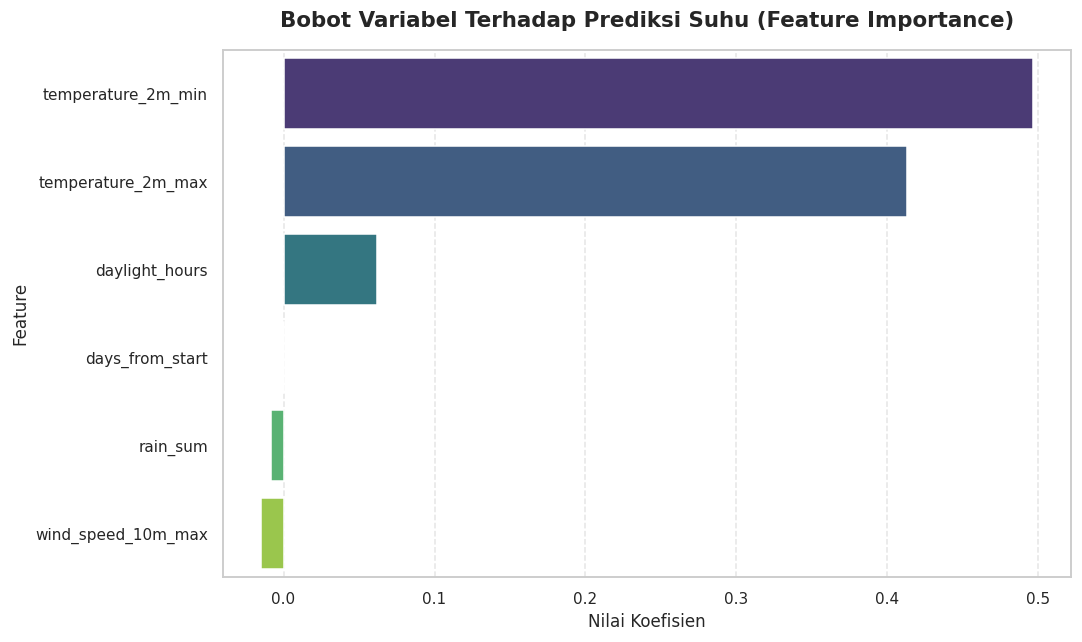

┌────────────────────────────────────────────────────────────┐
│ BOBOT KOEFISIEN MODEL │
├────────────────────────────────────────────────────────────┤


,Feature,Coefficient
2,temperature_2m_min,0.496304
1,temperature_2m_max,0.412842
3,daylight_hours,0.061675
0,days_from_start,-0.000028
4,rain_sum,-0.008155
5,wind_speed_10m_max,-0.014868


In [74]:
feature_importance = pd.DataFrame(
    {
        "Feature": X.columns,
        "Coefficient": model.coef_,
    }
).sort_values(by="Coefficient", ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x="Coefficient",
    y="Feature",
    data=feature_importance,
    palette="viridis",
)

plt.title(
    "Bobot Variabel Terhadap Prediksi Suhu (Feature Importance)",
    fontsize=14,
    fontweight="bold",
)

plt.xlabel("Nilai Koefisien")

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.5
)

plt.show()

print("┌────────────────────────────────────────────────────────────┐")
print("│ BOBOT KOEFISIEN MODEL │")
print("├────────────────────────────────────────────────────────────┤")

display(feature_importance)

┌────────────────────────────────────────────────────────────┐
│ FITUR TEMPORAL BERHASIL DIBENTUK │
├────────────────────────────────────────────────────────────┤


,time,year,month,day
0,2010-01-01,2010,1,1
1,2010-01-02,2010,1,2
2,2010-01-03,2010,1,3
3,2010-01-04,2010,1,4
4,2010-01-05,2010,1,5


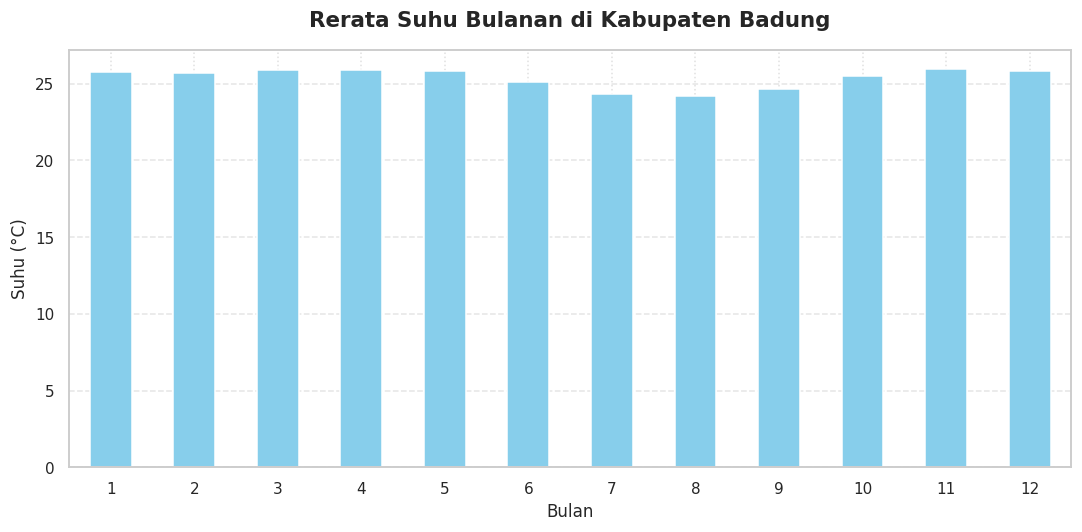

In [76]:
print("┌────────────────────────────────────────────────────────────┐")
print("│ FITUR TEMPORAL BERHASIL DIBENTUK │")
print("├────────────────────────────────────────────────────────────┤")

display(
    badung[
        ["time", "year", "month", "day"]
    ].head()
)

plt.figure(figsize=(10, 5))

badung.groupby("month")["temperature_2m_mean"].mean().plot(
    kind="bar",
    color="skyblue",
)

plt.title(
    "Rerata Suhu Bulanan di Kabupaten Badung",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Bulan")
plt.ylabel("Suhu (°C)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

In [78]:
features_final = [
    "year",
    "month",
    "day",
    "temperature_2m_max",
    "temperature_2m_min",
    "daylight_duration",
    "rain_sum",
    "wind_speed_10m_max",
]

X = badung[features_final]
y = badung["temperature_2m_mean"]

print("┌────────────────────────────────────────────────────────────┐")
print("│ FITUR AKHIR MODEL SIAP DIGUNAKAN │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Jumlah Fitur (X) : {X.shape[1]} kolom │")
print(f"│ [✓] Jumlah Observasi : {X.shape[0]} baris │")
print("└────────────────────────────────────────────────────────────┘")

┌────────────────────────────────────────────────────────────┐
│ FITUR AKHIR MODEL SIAP DIGUNAKAN │
├────────────────────────────────────────────────────────────┤
│ [✓] Jumlah Fitur (X) : 8 kolom │
│ [✓] Jumlah Observasi : 5844 baris │
└────────────────────────────────────────────────────────────┘


In [80]:
split_point = int(len(X) * 0.8)

model = LinearRegression()

y_pred_expanding = []

X_train_curr = X.iloc[:split_point].copy()
y_train_curr = y.iloc[:split_point].copy()

X_test_final = X.iloc[split_point:]

print(" Menjalankan Expanding Window Walk-Forward Validation...")

for i in range(len(X_test_final)):
    model.fit(X_train_curr, y_train_curr)

    y_pred_expanding.append(
        model.predict(X_test_final.iloc[[i]])[0]
    )

    X_train_curr = pd.concat(
        [X_train_curr, X_test_final.iloc[[i]]]
    )

    y_train_curr = pd.concat(
        [y_train_curr, y.iloc[[split_point + i]]]
    )

y_pred = np.array(y_pred_expanding)

y_test = y.iloc[split_point:]

print(
    f" Modeling selesai. Prediksi dilakukan pada {len(y_pred)} observasi."
)

 Menjalankan Expanding Window Walk-Forward Validation...
 Modeling selesai. Prediksi dilakukan pada 1169 observasi.


┌────────────────────────────────────────────────────────────┐
│ HASIL EVALUASI MODEL (EXPANDING) │
├────────────────────────────────────────────────────────────┤
│ [✓] MAE (Mean Absolute Error) : 0.2368 °C │
│ [✓] R-Squared (Akurasi) : 0.8987 │
└────────────────────────────────────────────────────────────┘


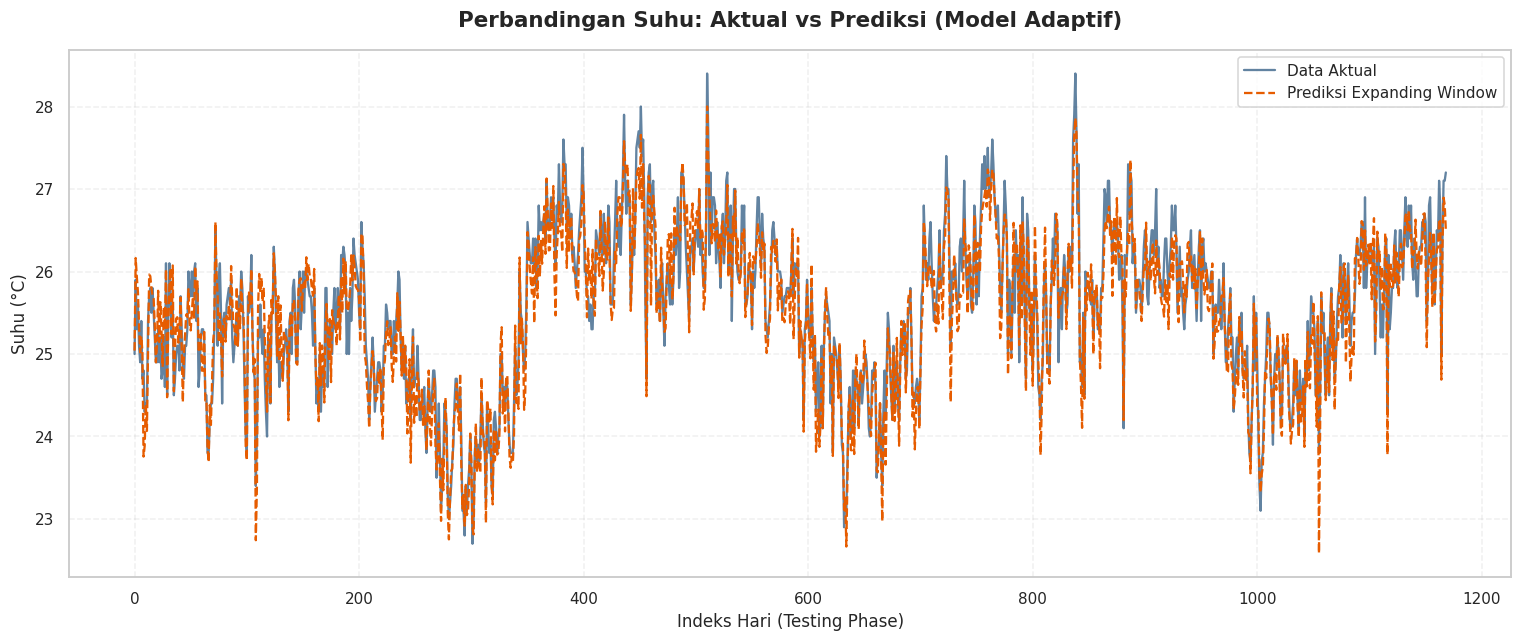

In [82]:
mae = mean_absolute_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("┌────────────────────────────────────────────────────────────┐")
print("│ HASIL EVALUASI MODEL (EXPANDING) │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] MAE (Mean Absolute Error) : {mae:.4f} °C │")
print(f"│ [✓] R-Squared (Akurasi) : {r2:.4f} │")
print("└────────────────────────────────────────────────────────────┘")

plt.figure(figsize=(14, 6))

navy = PALET_PREMIUM.get("navy_dark", "#1f4e79")
orange = "#E65C00"

plt.plot(
    y_test.values,
    label="Data Aktual",
    color=navy,
    alpha=0.7,
)

plt.plot(
    y_pred,
    label="Prediksi Expanding Window",
    color=orange,
    linestyle="--",
)

plt.title(
    "Perbandingan Suhu: Aktual vs Prediksi (Model Adaptif)",
    fontsize=14,
    fontweight="bold",
)

plt.xlabel("Indeks Hari (Testing Phase)")

plt.ylabel("Suhu (°C)")

plt.legend()

plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

┌────────────────────────────────────────────────────────────┐
│ HASIL AKHIR EVALUASI MODEL REGRESI │
├────────────────────────────────────────────────────────────┤
│ [✓] MAE (Mean Absolute Error) : 0.2368 °C │
│ [✓] MSE (Mean Squared Error) : 0.0892 °C² │
│ [✓] R-Squared (Akurasi) : 0.8987 │
└────────────────────────────────────────────────────────────┘


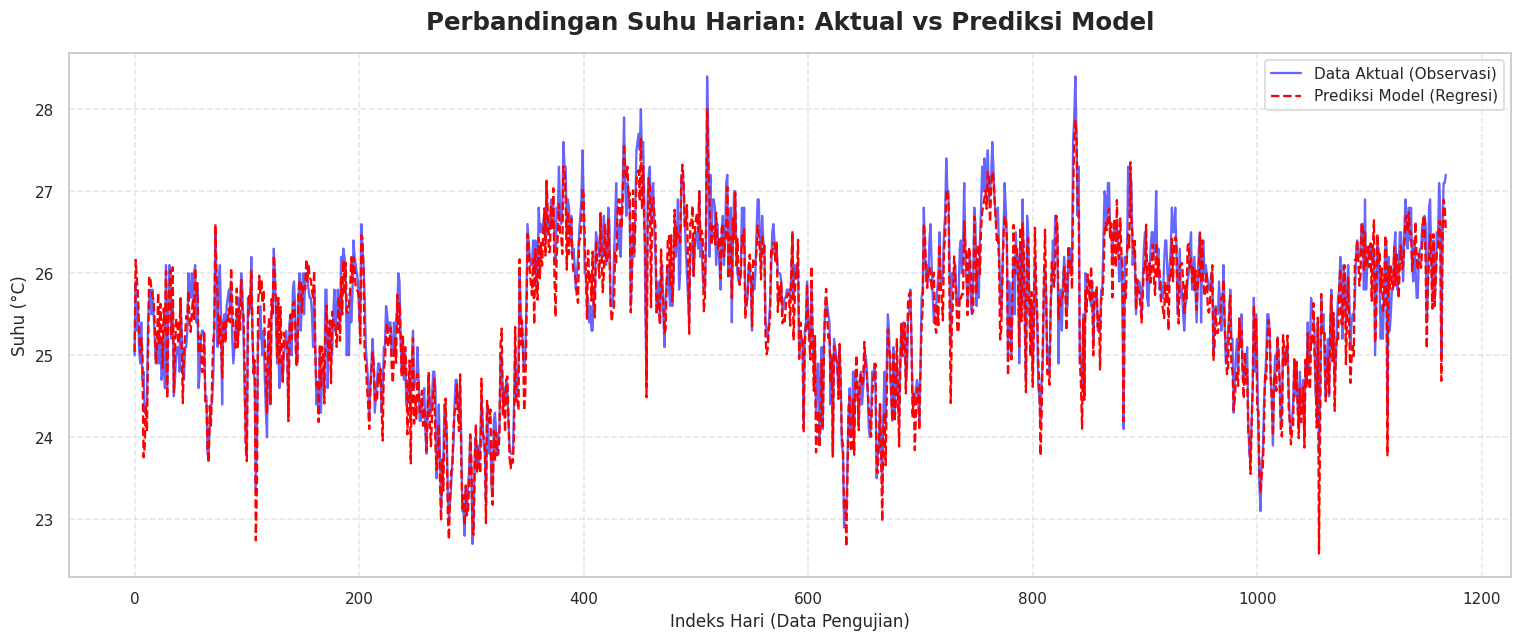

In [84]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(
    y_test,
    y_pred
)

print(
    "┌────────────────────────────────────────────────────────────┐"
)

print(
    "│ HASIL AKHIR EVALUASI MODEL REGRESI │"
)

print(
    "├────────────────────────────────────────────────────────────┤"
)

print(
    f"│ [✓] MAE (Mean Absolute Error) : {mae:.4f} °C │"
)

print(
    f"│ [✓] MSE (Mean Squared Error) : {mse:.4f} °C² │"
)

print(
    f"│ [✓] R-Squared (Akurasi) : {r2:.4f} │"
)

print(
    "└────────────────────────────────────────────────────────────┘"
)

plt.figure(
    figsize=(14, 6)
)

plt.plot(
    y_test.values,
    label="Data Aktual (Observasi)",
    color="blue",
    alpha=0.6,
)

plt.plot(
    y_pred,
    label="Prediksi Model (Regresi)",
    color="red",
    linestyle="--",
)

plt.title(
    "Perbandingan Suhu Harian: Aktual vs Prediksi Model",
    fontsize=16,
    fontweight="bold",
)

plt.xlabel(
    "Indeks Hari (Data Pengujian)"
)

plt.ylabel(
    "Suhu (°C)"
)

plt.legend()

plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)

plt.show()

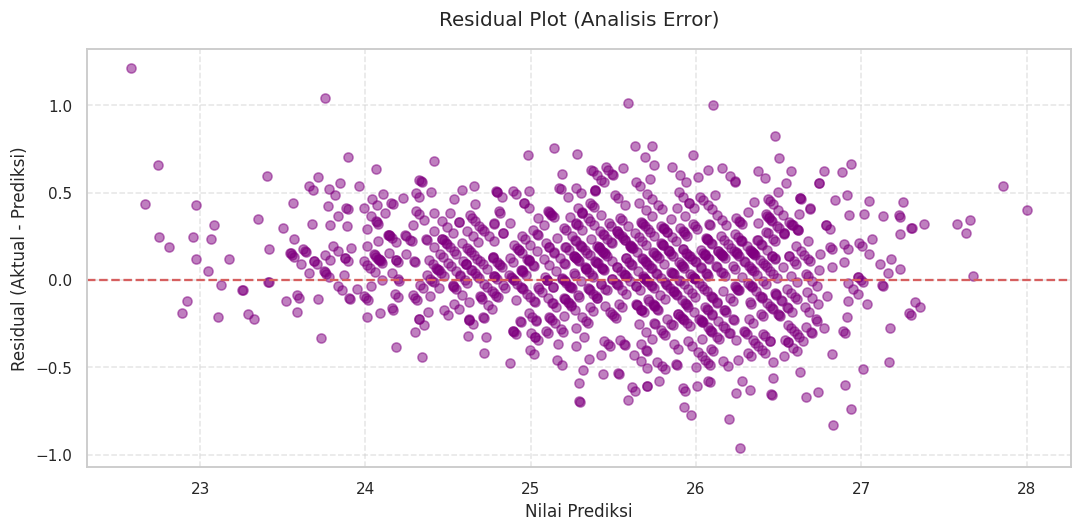

In [86]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 5))
plt.scatter(y_pred, residuals, alpha=0.5, color='purple')
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residual Plot (Analisis Error)')
plt.xlabel('Nilai Prediksi')
plt.ylabel('Residual (Aktual - Prediksi)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [88]:
#Nilai MAE
mae = mean_absolute_error(
    y_test,
    y_pred
)
print(
      "MAE =",
      mae
)

MAE = 0.2367807770970451


In [90]:
#Nilai RMSE
rmse = np.sqrt(
    mean_squared_error(
    y_test,
    y_pred
  )
)
print(
    "RMSE =",
    rmse
)

RMSE = 0.29863977705377664


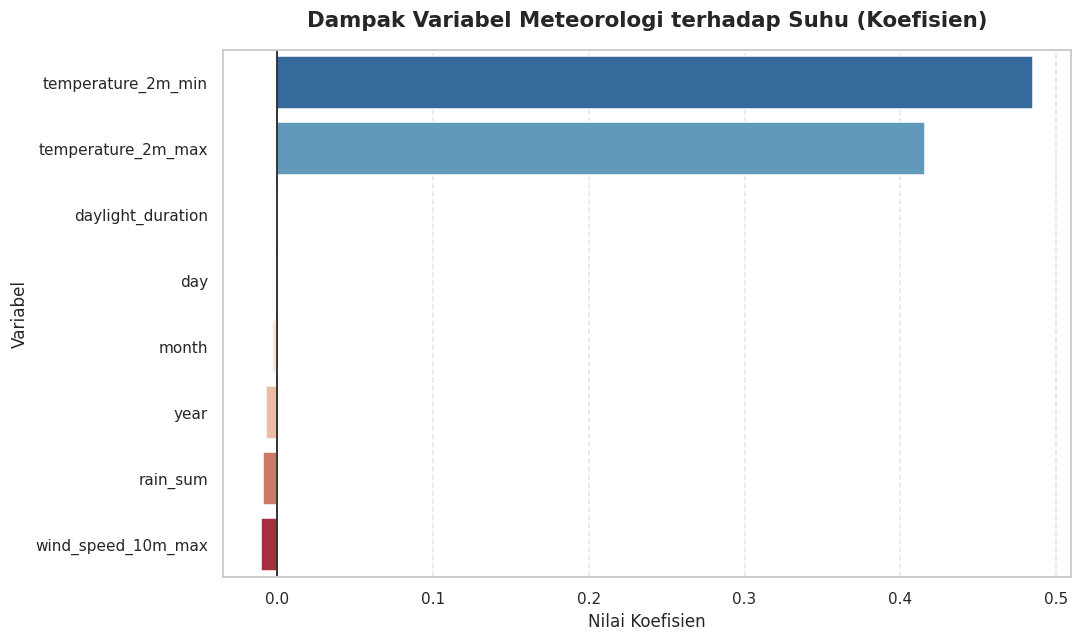

Tabel Koefisien Regresi:


,Variabel,Koefisien
4,temperature_2m_min,0.485096
3,temperature_2m_max,0.415891
5,daylight_duration,0.000023
2,day,-0.000283
1,month,-0.003607
0,year,-0.007198
6,rain_sum,-0.009427
7,wind_speed_10m_max,-0.010535


In [92]:
coef = pd.DataFrame(
    {
        "Variabel": X.columns,
        "Koefisien": model.coef_,
    }
)

coef_sorted = coef.sort_values(
    by="Koefisien",
    ascending=False,
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x="Koefisien",
    y="Variabel",
    data=coef_sorted,
    palette="RdBu_r",
)

plt.title(
    "Dampak Variabel Meteorologi terhadap Suhu (Koefisien)",
    fontsize=14,
    fontweight="bold",
)

plt.axvline(
    x=0,
    color="black",
    linestyle="-",
    linewidth=1,
)

plt.xlabel("Nilai Koefisien")

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

plt.show()

print(
    "Tabel Koefisien Regresi:"
)

display(
    coef_sorted
)

In [94]:
intercept = model.intercept_
print("┌────────────────────────────────────────────────────────────┐")
print("│ INTERSEP MODEL (BASELINE) │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ Intercept (β₀) : {intercept:.4f} │")
print("└────────────────────────────────────────────────────────────┘")
print("\nInterpretasi:")
print("Nilai ini menunjukkan suhu dasar (baseline) yang diprediksi oleh model")
print("ketika semua variabel cuaca diasumsikan berada pada titik nol.")

┌────────────────────────────────────────────────────────────┐
│ INTERSEP MODEL (BASELINE) │
├────────────────────────────────────────────────────────────┤
│ Intercept (β₀) : 16.1104 │
└────────────────────────────────────────────────────────────┘

Interpretasi:
Nilai ini menunjukkan suhu dasar (baseline) yang diprediksi oleh model
ketika semua variabel cuaca diasumsikan berada pada titik nol.


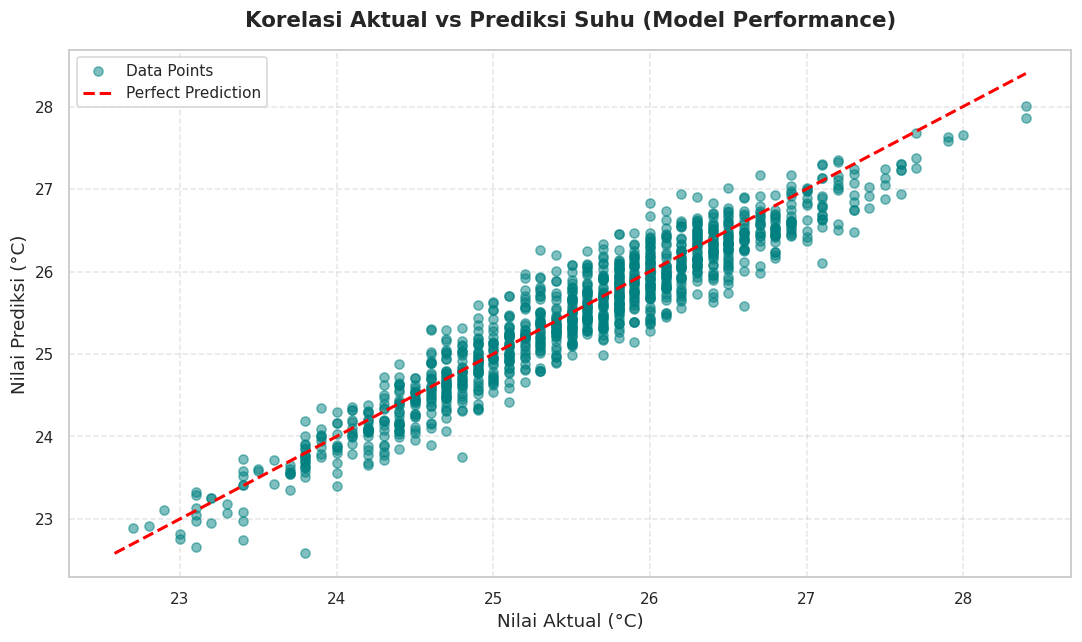

In [96]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5,
    color="teal",
    label="Data Points",
)

min_val = min(
    y_test.min(),
    y_pred.min()
)

max_val = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [
        min_val,
        max_val
    ],
    [
        min_val,
        max_val
    ],
    color="red",
    linestyle="--",
    lw=2,
    label="Perfect Prediction",
)

plt.xlabel(
    "Nilai Aktual (°C)",
    fontsize=12
)

plt.ylabel(
    "Nilai Prediksi (°C)",
    fontsize=12
)

plt.title(
    "Korelasi Aktual vs Prediksi Suhu (Model Performance)",
    fontsize=14,
    fontweight="bold",
)

plt.legend()

plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)

plt.show()

┌────────────────────────────────────────────────────────────┐
│ ANALISIS DISTRIBUSI RESIDUAL │
├────────────────────────────────────────────────────────────┤
│ [✓] Rata-rata Residual (Bias) : 0.0664 °C │
└────────────────────────────────────────────────────────────┘


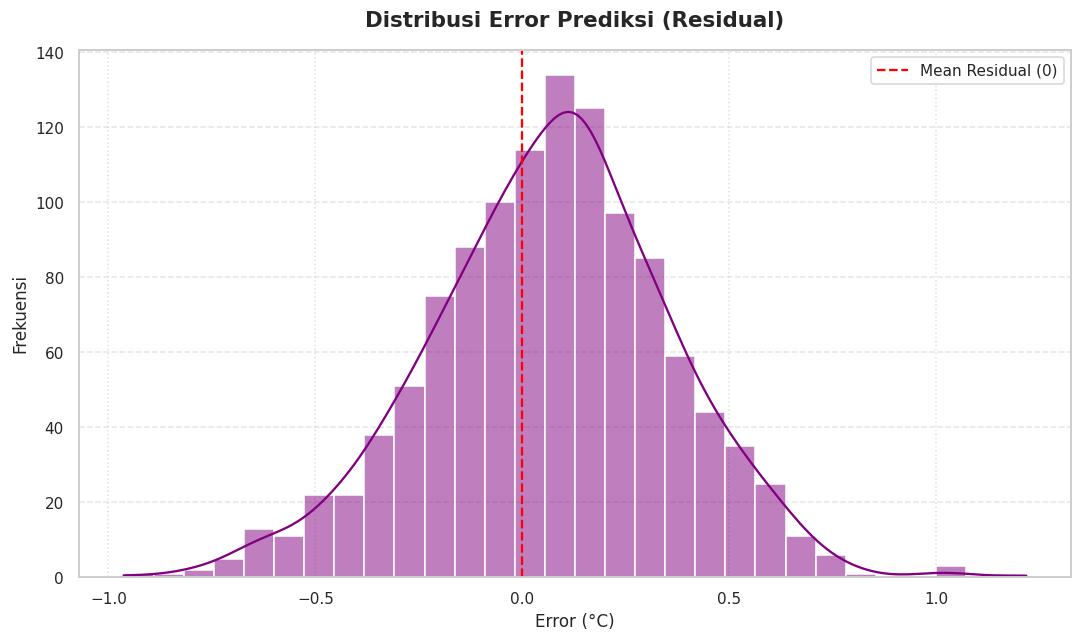

In [98]:
residual = y_test - y_pred

mean_residual = residual.mean()

print("┌────────────────────────────────────────────────────────────┐")
print("│ ANALISIS DISTRIBUSI RESIDUAL │")
print("├────────────────────────────────────────────────────────────┤")
print(f"│ [✓] Rata-rata Residual (Bias) : {mean_residual:.4f} °C │")
print("└────────────────────────────────────────────────────────────┘")

plt.figure(
    figsize=(10, 6)
)

sns.histplot(
    residual,
    kde=True,
    color="purple",
    bins=30,
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Mean Residual (0)",
)

plt.title(
    "Distribusi Error Prediksi (Residual)",
    fontsize=14,
    fontweight="bold",
)

plt.xlabel(
    "Error (°C)"
)

plt.ylabel(
    "Frekuensi"
)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.show()

In [99]:
badung['time'] = pd.to_datetime(badung['time'])

kamus_hari = {
    0: 'Senin',
    1: 'Selasa',
    2: 'Rabu',
    3: 'Kamis',
    4: 'Jumat',
    5: 'Sabtu',
    6: 'Minggu'
}

badung[
    'day'
] = badung[
    'time'
].dt.dayofweek.map(
    kamus_hari
)

badung.to_excel(
    'Data Bersih.xlsx',
    index=False
)

display(
    badung.head()
)

,time,year,month,day,temperature_2m_mean,temperature_2m_max,temperature_2m_min,daylight_duration,rain_sum,wind_speed_10m_max,temp_trend,daylight_hours,wind_trend,days_from_start
0,2010-01-01,2010,1,Jumat,26.2,27.9,24.4,45409.65,12.9,7.9,NaN,12.613792,NaN,0
1,2010-01-02,2010,1,Sabtu,26.6,28.9,24.2,45402.18,3.2,9.0,NaN,12.611717,NaN,1
2,2010-01-03,2010,1,Minggu,26.9,29.1,24.7,45394.10,7.8,11.0,NaN,12.609472,NaN,2
3,2010-01-04,2010,1,Senin,26.9,28.8,25.6,45385.39,5.9,13.8,NaN,12.607053,NaN,3
4,2010-01-05,2010,1,Selasa,26.6,28.7,25.1,45376.07,5.0,11.0,NaN,12.604464,NaN,4
